# TP3 - Clasificación de uso del suelo con CNNs (EuroSAT RGB)
### Tecnología Digital VI - Inteligencia Artificial

**Integrantes:** Manuel Milde, Luciano Pozzoli

Este notebook resuelve el TP3: clasificar el **uso del suelo** de recortes de
imágenes satelitales Sentinel-2 (dataset **EuroSAT**, versión **RGB**) en
**10 clases balanceadas** (`AnnualCrop`, `Forest`, `HerbaceousVegetation`,
`Highway`, `Industrial`, `Pasture`, `PermanentCrop`, `Residential`, `River`,
`SeaLake`) usando Redes Neuronales Convolucionales en **PyTorch**.

Estructura del notebook (el **Informe** con el resumen de resultados está a continuación):

1. Setup y carga de datos
2. Análisis Exploratorio (EDA)
3. Pipeline de datos y Data Augmentation
4. Arquitectura custom (CNN desde cero)
5. Entrenamiento desde cero + monitoreo de métricas y de gradientes
6. Evaluación en test y análisis de errores (matriz de confusión)
7. Espacio latente (PCA / t-SNE / UMAP)
8. Transfer Learning con ResNet18 preentrenada en ImageNet
9. Comparación: CNN custom vs Transfer Learning
10. Conclusiones finales

La lógica reutilizable (datos, augmentation, modelos, loop de entrenamiento,
monitor de gradientes, evaluación y espacio latente) vive en
`src/eurosat_cnn/` — este notebook la importa y se enfoca en el análisis,
los resultados y las decisiones tomadas.

## Informe

### Objetivo y datos

Clasificamos el **uso del suelo** de recortes satelitales Sentinel-2 del
dataset **EuroSAT RGB** (27.000 imágenes de 64×64 px, 10 m/píxel, 10
clases casi balanceadas) con Redes Neuronales Convolucionales en PyTorch.
Usamos la partición del dataset de Kaggle: 18.900 imágenes de train, 5.400
de validación y 2.700 de test, sin imágenes repetidas entre splits. El test
se usó una única vez por modelo, con los pesos de la mejor época según
validación.

### Metodología

- **Data augmentation con invarianzas geométricas** (sección 3): las
  imágenes son cenitales y no tienen un "arriba" canónico. Por eso usamos
  rotaciones de 90° y flips (las 8 orientaciones posibles, sin bordes
  vacíos), un recorte aleatorio suave y un *color jitter* chico.
- **CNN custom desde cero** (secciones 4-5): 4 bloques
  [Conv3×3-BN-ReLU]×2 + MaxPool, Global Average Pooling y un embedding de
  128 dimensiones; 1,2 M de parámetros. Se entrenó con AdamW,
  `OneCycleLR`, *label smoothing* 0,1 y 60 épocas. Además monitoreamos la
  norma del gradiente de cada capa en las primeras épocas.
- **Análisis** (secciones 6-7): métricas por clase, matriz de confusión,
  ejemplos mal clasificados y proyección del espacio latente previo a la
  capa final con PCA, t-SNE y UMAP (con silhouette score).
- **Transfer learning** (sección 8): ResNet18 preentrenada en ImageNet en
  tres variantes: solo `layer4`+`fc` a 64 px, fine-tuning completo a 64 px
  y fine-tuning completo a 224 px.
- **Test-Time Augmentation (TTA):** en test promediamos las predicciones
  de las 8 orientaciones de cada imagen.

### Resultados

| Modelo | Parámetros entrenables | Épocas hasta 95% de val | Seg/época | Min totales | Test acc (sin / con TTA) | F1-macro (con TTA) |
|---|---|---|---|---|---|---|
| CNN custom | 1,2 M | 23 | 3,4 | 4,0 | 97,85% / 97,81% | 0,978 |
| ResNet18 `layer4`+`fc`, 64 px | 8,4 M | no llega | 2,2 | 0,7 | 95,81% / 97,52% | 0,974 |
| ResNet18 fine-tuning, 64 px | 11,2 M | 3 | 3,5 | 0,7 | 97,04% / 97,74% | 0,977 |
| **ResNet18 fine-tuning, 224 px** | 11,2 M | **2** | 22,6 | 4,8 | **98,52% / 98,59%** | **0,986** |

- **Mejor modelo:** ResNet18 con fine-tuning completo a 224 px, con
  **98,6% de accuracy en test** (38 errores sobre 2.700 imágenes). Pasa el
  93% de validación después de una sola época.
- **La CNN custom**, 9 veces más chica y entrenada desde cero, llega a
  **97,8%** e iguala al fine-tuning de ResNet18 a la misma resolución.
- **Gradientes sanos:** en la CNN custom todas las capas reciben gradientes
  del mismo orden de magnitud y no hay explosiones. En una red de contraste
  con sigmoide y sin BatchNorm, el gradiente de la primera capa es 2·10⁸
  veces menor que el de la última.
- **Errores:** se concentran en las coberturas vegetales (`PermanentCrop`,
  `HerbaceousVegetation`, `AnnualCrop`) y en `Industrial` → `Residential`,
  clases vecinas en color, textura y semántica.
- **Espacio latente:** antes de la capa final las clases forman clusters
  claros (silhouette 0,72 en el espacio de 128 dimensiones), mientras que
  en los píxeles crudos están mezcladas (−0,11).

### Optimización: primera versión vs versión final

En una primera versión el entrenamiento usaba el `DataLoader` clásico, con
las augmentations en CPU. Medimos que el cuello de botella era la CPU y no
la GPU: ResNet18, con 9 veces más parámetros, tardaba casi lo mismo por
época que la CNN custom (12,6 s vs 10,8 s). Pasamos el dataset completo a
la memoria de la GPU (332 MB), hicimos las augmentations por batch en la
GPU y agregamos precisión mixta `bfloat16`.

| | Versión 1 | Versión final |
|---|---|---|
| Lectura + augmentation de una época de train | ~11 s en régimen (24 s medidos, incluyendo el arranque de los procesos en Windows) | **0,74 s** (GPU) |
| Seg/época, CNN custom | 10,8 | **3,4** |
| Seg/época, ResNet18 fine-tuning 64 px | 12,6 | **3,5** |
| CNN custom: épocas / minutos totales | 30 / 7,4 | 60 / **4,0** |
| CNN custom: test accuracy | 96,93% | **97,85%** |
| CNN custom: errores en test | 83 | **58** |
| Mejor modelo en test | 97,33% (ResNet 64 px) | **98,59%** (ResNet 224 px) |

La velocidad ganada permitió entrenar el doble de épocas en la mitad del
tiempo y sumar la variante a 224 px. Comparando los resultados de las dos
versiones vimos que diferencias menores a ~0,3-0,5 puntos (por ejemplo,
ResNet18 a 64 px: 97,33% en la primera corrida y 97,04% en la segunda) son
variación normal entre corridas y no deben interpretarse como mejoras
reales.

### Conclusiones

1. Las **invarianzas geométricas de las imágenes cenitales** se aprovechan
   dos veces: en el entrenamiento (augmentation) y en la inferencia (TTA).
   El TTA ayuda mucho a los modelos menos adaptados al dominio (+1,7
   puntos en ResNet con el backbone congelado) y casi nada a los que ya
   aprendieron la invarianza.
2. **Transfer learning con fine-tuning completo** es la mejor opción:
   converge en 1-2 épocas y da la mejor accuracy, sobre todo **a la
   resolución con la que se preentrenó** (224 px). Congelar el backbone
   rinde peor por el *domain shift* entre ImageNet y las imágenes
   satelitales.
3. Una **CNN chica bien diseñada** (BatchNorm, ReLU, init de He, GAP,
   regularización) es una alternativa liviana muy competitiva: 97,8% con
   1,2 M de parámetros.
4. Los errores que quedan son de **clases vegetales con colores casi
   idénticos**, cuya diferencia es en parte temporal (fenología). Las
   mejoras naturales serían usar las 13 bandas multiespectrales de
   Sentinel-2 (por ejemplo el infrarrojo cercano) o series temporales.
5. En imágenes chicas, **optimizar el pipeline de datos** importa tanto
   como el modelo: llevar la augmentation a la GPU hizo cada época unas 3
   veces más rápida.

## 1. Setup y carga de datos

**Dónde correrlo:** se recomienda un entorno con GPU (Google Colab o un
notebook de Kaggle). En CPU funciona, pero el entrenamiento completo tarda
bastante más.

**Descarga del dataset** (https://www.kaggle.com/datasets/apollo2506/eurosat-dataset):

- **Kaggle notebook:** agregar el dataset con *Add Input* y setear
  `EUROSAT_DIR = "/kaggle/input/eurosat-dataset"`.
- **Colab / local:** con la API de Kaggle (necesita `kaggle.json`):
  ```bash
  pip install kaggle
  kaggle datasets download -d apollo2506/eurosat-dataset -p data/raw --unzip
  ```

El loader (`data.load_splits`) busca automáticamente la carpeta con las 10
subcarpetas de clase (ignora la versión multiespectral `EuroSATallBands`).
Si encuentra los CSVs `train.csv` / `validation.csv` / `test.csv` del dataset
de Kaggle usa esa partición; si no, hace un split estratificado 70/15/15
reproducible.

In [1]:
# --- Solo en Colab: descomentar para clonar/subir el proyecto e instalar deps ---
# !pip install -q umap-learn kaggle
# from google.colab import files; files.upload()  # subir kaggle.json
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d apollo2506/eurosat-dataset -p data/raw --unzip

In [2]:
# torch PRIMERO: en Windows, importarlo después de numpy/matplotlib puede
# fallar con "WinError 1114 ... c10.dll" (conflicto de DLLs).
import torch

import os
import sys
import time
from pathlib import Path

# Permite importar el paquete src/eurosat_cnn desde el notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Ruta al dataset (sobreescribir si está en otro lado, ej. en Kaggle)
# os.environ["EUROSAT_DIR"] = "/kaggle/input/eurosat-dataset"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from eurosat_cnn import config, data
from eurosat_cnn.utils import set_seed, get_device, count_params
from eurosat_cnn.models import EuroSATCNN, build_resnet18, resnet_param_groups
from eurosat_cnn.training import fit
from eurosat_cnn.gradients import GradientMonitor
from eurosat_cnn.evaluate import (
    predict, metrics_summary, report_df, plot_confusion_matrix,
    top_confusions, plot_misclassified,
)
from eurosat_cnn.latent import (
    extract_features, raw_pixels, project, separability_scores,
    plot_embeddings, plot_embedding_3d,
)
from eurosat_cnn.plotting import (
    plot_history, plot_comparison, epochs_to_reach,
    show_batch_by_class, show_augmentations,
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = config.RANDOM_STATE
set_seed(RANDOM_STATE)
DEVICE = get_device()
torch.backends.cudnn.benchmark = True  # elige los kernels de convolución más rápidos
print("Device:", DEVICE, "| PyTorch", torch.__version__)

Device: cuda | PyTorch 2.14.1+cu126


In [3]:
# --- Hiperparámetros del experimento ---------------------------------------
# SMOKE_TEST=True corre todo con muy pocos datos/épocas: sirve solo para
# verificar que el pipeline funciona de punta a punta (NO para reportar).
SMOKE_TEST = os.environ.get("EUROSAT_SMOKE") == "1"

EPOCHS_CUSTOM = 2 if SMOKE_TEST else 60   # CNN desde cero
EPOCHS_TL = 2 if SMOKE_TEST else 10       # ResNet18 (converge mucho antes)
GRAD_MONITOR_EPOCHS = 2 if SMOKE_TEST else 3
MAX_PER_CLASS = 30 if SMOKE_TEST else None
PRETRAINED = not SMOKE_TEST               # pesos de ImageNet (requiere internet)
TL_IMG_SIZE = 64                          # misma resolución que la CNN custom (comparación justa)
TL_HIRES_SIZE = 96 if SMOKE_TEST else 224 # resolución de ImageNet (variante optimizada)
BATCH_SIZE = 32 if SMOKE_TEST else config.BATCH_SIZE
LABEL_SMOOTHING = 0.1                     # regularización de la CNN custom
USE_AMP = True                            # precisión mixta bfloat16 + channels_last (solo GPU)

def savefig(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

In [4]:
splits = data.load_splits(max_per_class=MAX_PER_CLASS)
splits["train"].head()

Dataset en C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\data\raw\EuroSAT (CSVs oficiales del dataset de Kaggle)
  train:  18900 imágenes
  val  :   5400 imágenes
  test :   2700 imágenes


,path,label,class_name
0,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,0,AnnualCrop
1,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,2,HerbaceousVegetation
2,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,6,PermanentCrop
3,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,4,Industrial
4,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,2,HerbaceousVegetation


## 2. Análisis Exploratorio (EDA)

Objetivo: verificar el balance de clases y la integridad de los splits,
mirar ejemplos de cada clase para anticipar qué pares van a ser difíciles de
distinguir, y calcular las estadísticas por canal para normalizar.

### 2.1 Distribución de clases por split

,train,val,test,total
class_name,,,,
AnnualCrop,2100,600,300,3000
Forest,2100,600,300,3000
HerbaceousVegetation,2100,600,300,3000
Highway,1750,500,250,2500
Industrial,1750,500,250,2500
Pasture,1400,400,200,2000
PermanentCrop,1750,500,250,2500
Residential,2100,600,300,3000
River,1750,500,250,2500


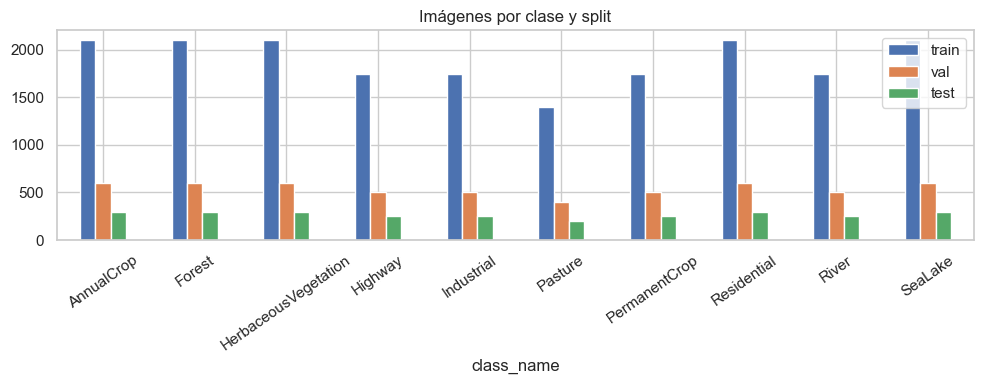

Intersección train∩val: 0 | train∩test: 0 | val∩test: 0


In [5]:
counts = pd.DataFrame({k: v["class_name"].value_counts() for k, v in splits.items()})
counts = counts.reindex(config.CLASSES)
counts["total"] = counts.sum(axis=1)
display(counts)

fig, ax = plt.subplots(figsize=(10, 4))
counts[["train", "val", "test"]].plot(kind="bar", ax=ax)
ax.set_title("Imágenes por clase y split")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig(fig, "eda_clases"); plt.show()

# Chequeo de leakage: ninguna imagen debería estar en dos splits a la vez
paths = {k: set(v["path"]) for k, v in splits.items()}
print("Intersección train∩val:", len(paths["train"] & paths["val"]),
      "| train∩test:", len(paths["train"] & paths["test"]),
      "| val∩test:", len(paths["val"] & paths["test"]))

El dataset es **aproximadamente balanceado** (entre 2000 y 3000 imágenes por
clase en el EuroSAT completo; las clases con menos ejemplos son `Pasture`
—2000— e `Highway`/`Industrial`/`PermanentCrop`/`River` —2500—). Por eso
**accuracy** es una métrica razonable, pero igual reportamos **F1-macro** y
las métricas por clase para no esconder un mal desempeño en las clases más
chicas.

### 2.2 Ejemplos por clase y estadísticas por canal

Tamaño de imagen (C, H, W): (3, 64, 64)


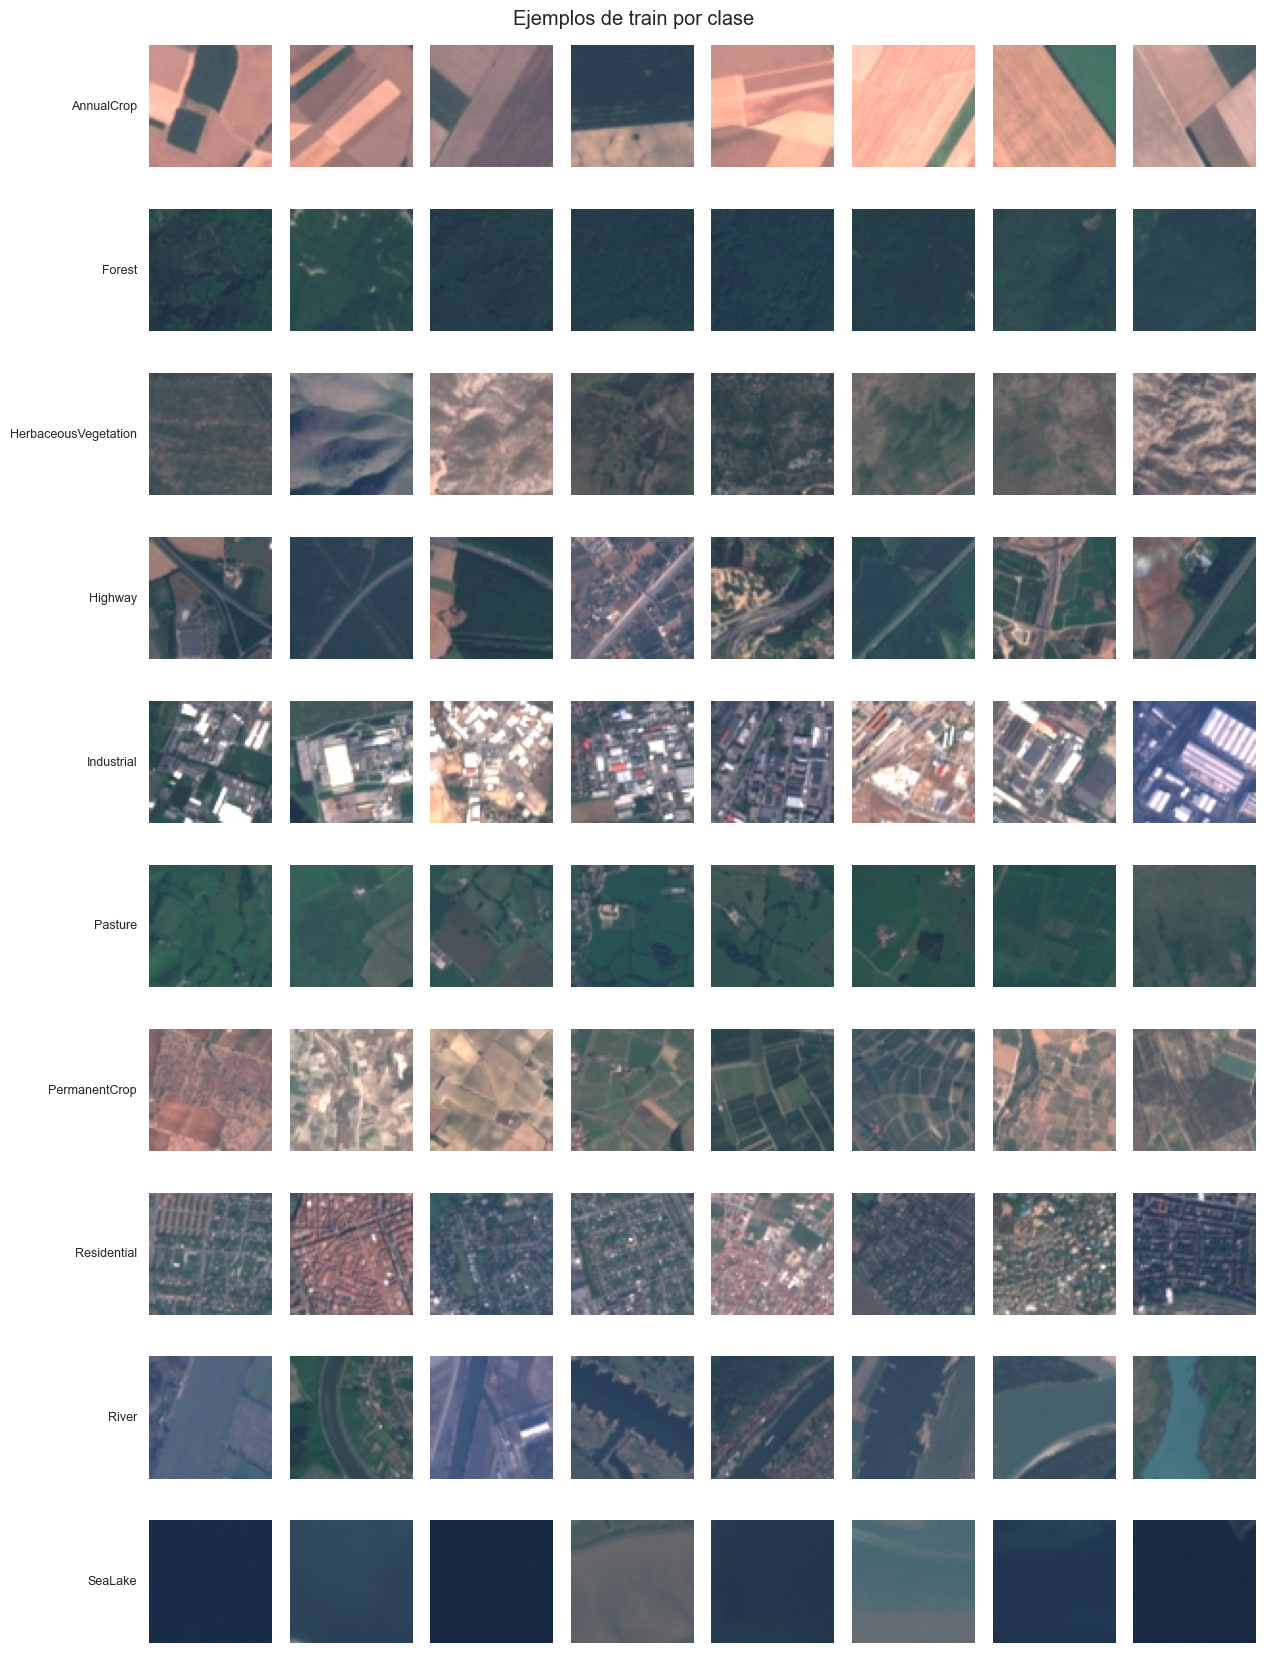

In [6]:
from torchvision import transforms as T

viz_ds = data.EuroSATDataset(splits["train"], T.ToTensor())
img0, _ = viz_ds[0]
print("Tamaño de imagen (C, H, W):", tuple(img0.shape))

fig = show_batch_by_class(viz_ds, splits["train"]["label"], (0, 0, 0), (1, 1, 1),
                          n_per_class=8, title="Ejemplos de train por clase")
savefig(fig, "eda_ejemplos"); plt.show()

In [7]:
# Cargamos TODAS las imágenes una sola vez a tensores uint8 (la primera vez
# tarda ~1 min; después se lee de un cache en outputs/cache/).
t0 = time.perf_counter()
tensors = {k: data.preload_split(v) for k, v in splits.items()}
# Una sola copia en la GPU, compartida por todos los loaders (CNN custom y ResNet)
tensors = {k: (x.to(DEVICE), y.to(DEVICE)) for k, (x, y) in tensors.items()}
print({k: tuple(x.shape) for k, (x, _) in tensors.items()},
      f"| {sum(x.numel() for x, _ in tensors.values()) / 1e6:.0f} MB | {time.perf_counter() - t0:.1f}s")

# Media/desvío por canal sobre TODO train (para normalizar la CNN custom).
# Para ResNet18 se usan las estadísticas de ImageNet, que son las que vio
# la red durante su preentrenamiento.
EUROSAT_MEAN, EUROSAT_STD = data.tensor_mean_std(tensors["train"][0])
print("Media RGB:", np.round(EUROSAT_MEAN, 4))
print("Std   RGB:", np.round(EUROSAT_STD, 4))

{'train': (18900, 3, 64, 64), 'val': (5400, 3, 64, 64), 'test': (2700, 3, 64, 64)} | 332 MB | 0.6s
Media RGB: [0.3445 0.3803 0.4078]
Std   RGB: [0.2031 0.1371 0.1157]


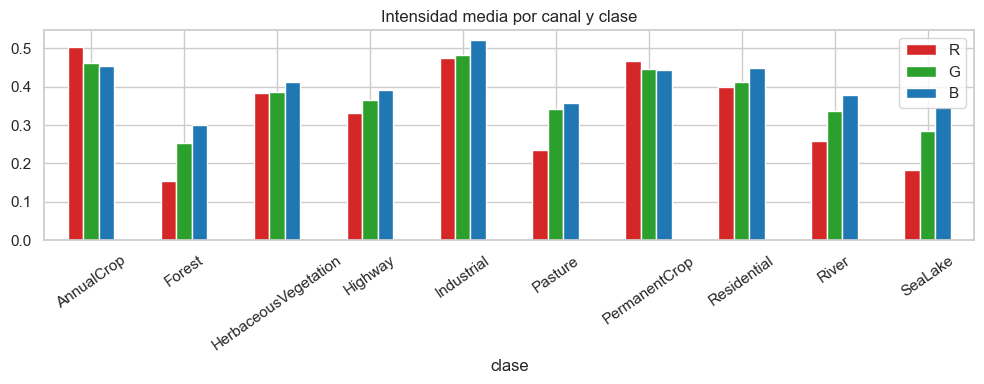

In [8]:
# Color medio por clase: ¿cuánta información trae solo el color?
rows = []
for c in config.CLASSES:
    sub = splits["train"][splits["train"]["class_name"] == c].sample(
        min(150, (splits["train"]["class_name"] == c).sum()), random_state=0)
    m = np.mean([viz_ds.transform(data.Image.open(p).convert("RGB")).mean((1, 2)).numpy()
                 for p in sub["path"]], axis=0)
    rows.append({"clase": c, "R": m[0], "G": m[1], "B": m[2]})
color_df = pd.DataFrame(rows).set_index("clase")

fig, ax = plt.subplots(figsize=(10, 4))
color_df.plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], ax=ax)
ax.set_title("Intensidad media por canal y clase")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig(fig, "eda_color_por_clase"); plt.show()

**Conclusiones del EDA:**

- **Partición:** se usaron los CSVs oficiales del dataset de Kaggle:
  18.900 imágenes de train, 5.400 de validación y 2.700 de test (70/20/10),
  estratificados y **sin imágenes repetidas entre splits** (intersecciones
  vacías → sin leakage).
- **Balance:** entre 2.000 (`Pasture`) y 3.000 imágenes por clase. El
  desbalance es leve (1,5×), así que accuracy es representativa, pero igual
  reportamos F1-macro.
- **Color:** la intensidad media por canal ya separa grupos de clases.
  `Forest`, `SeaLake`, `River` y `Pasture` son oscuras en el rojo (la
  vegetación densa y el agua absorben el rojo), mientras que `AnnualCrop`,
  `PermanentCrop`, `Industrial` y `Residential` son claras y con los tres
  canales parecidos (suelo desnudo, techos). En cambio, **`AnnualCrop` y
  `PermanentCrop` tienen un perfil de color casi idéntico**, y
  `HerbaceousVegetation` queda en el medio de todas: para separarlas la red
  tiene que apoyarse en la **textura y la geometría**. Son las candidatas
  naturales a confundirse.
- `Highway` y `River` (estructuras lineales sobre fondo vegetal) e
  `Industrial` y `Residential` (superficies construidas) son otros dos
  pares a vigilar.
- **Normalización:** sobre todo train, la media RGB es (0,345; 0,380;
  0,408) y el desvío (0,203; 0,137; 0,116). Son distintos de los de
  ImageNet, por eso la CNN custom usa los propios y ResNet18 los de
  ImageNet.

## 3. Pipeline de datos y Data Augmentation

Las imágenes satelitales se toman en **vista cenital (nadir)**: no hay un
"arriba" o "abajo" canónico. Un campo de cultivo rotado 90° o espejado sigue
siendo exactamente la misma clase. Por eso las augmentations más pertinentes
son **geométricas e invariantes a la orientación** (implementadas en
`data.build_transforms`):

| Transformación | Justificación |
|---|---|
| `RandomHorizontalFlip` + `RandomVerticalFlip` | No hay orientación privilegiada en una imagen cenital. |
| `RandomRot90` (0/90/180/270°) | Igual que los flips; además, al ser múltiplos de 90° **no genera esquinas vacías** que haya que rellenar (a diferencia de una rotación arbitraria). Flips + rot90 cubren el grupo diédrico completo (8 orientaciones). |
| `RandomResizedCrop(scale=0.8-1)` | Robustez a pequeños desplazamientos y cambios de escala del recorte. Se mantiene suave porque la imagen es de solo 64×64. |
| `ColorJitter` suave (±10%) | Simula diferencias de iluminación, estación del año y atmósfera entre adquisiciones. Es **chico a propósito**: el color es muy informativo (agua vs. vegetación vs. suelo) y alterarlo mucho podría cambiar la semántica (ej. un pasto verde que "parezca" seco). |

**No** usamos augmentations que rompan la física de la imagen, como
rotaciones arbitrarias con relleno, *cutout* grandes o cambios de tono
(hue) fuertes. Validación y test **no** llevan augmentation (solo
normalización).

**Optimización: pipeline en GPU.** En una primera versión usamos el
`DataLoader` clásico, con las transformaciones de `torchvision` aplicadas
en CPU (abajo se muestra, como referencia, esa definición). Medimos ~11 s
por época para la CNN custom y ~12,6 s para ResNet18, casi lo mismo aunque
ResNet18 tiene 9× más parámetros: el cuello de botella era **la CPU**
(decodificar los JPEG y transformarlos), no la GPU. Como el dataset entero
ocupa solo ~330 MB como `uint8`, lo cargamos **una sola vez a la memoria de
la GPU** y aplicamos las mismas augmentations **por batch en la GPU**
(`data.gpu_augment`), con parámetros distintos para cada imagen. El
`GPUBatchLoader` tiene la misma interfaz que un `DataLoader` (se itera y
devuelve `(x, y)`), así que el loop de entrenamiento no cambia.

In [9]:
train_tf, eval_tf = data.build_transforms(EUROSAT_MEAN, EUROSAT_STD, augment=True)
print("Train transform:\n", train_tf)
print("\nEval transform:\n", eval_tf)

# Pipeline usado para entrenar: todo en GPU
loaders = data.make_gpu_loaders(tensors, EUROSAT_MEAN, EUROSAT_STD, DEVICE, batch_size=BATCH_SIZE)
xb, yb = next(iter(loaders["train"]))
print("\nBatch de train:", tuple(xb.shape), xb.device, "| labels:", tuple(yb.shape))

# Benchmark: una época de lectura + augmentation, DataLoader en CPU vs GPU
cpu_loader = data.make_dataloaders(splits, train_tf, eval_tf, batch_size=BATCH_SIZE)["train"]
for name, ld in [("DataLoader CPU (torchvision)", cpu_loader), ("GPUBatchLoader", loaders["train"])]:
    t0 = time.perf_counter()
    for x, y in ld:
        x = x.to(DEVICE, non_blocking=True)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    print(f"{name:<30}: {time.perf_counter() - t0:6.2f} s por época (solo datos, sin modelo)")
del cpu_loader

Train transform:
 Compose(
    RandomResizedCrop(size=(64, 64), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRot90()
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=(0.3444953988395125, 0.380347455648926, 0.40780442656663335), std=(0.20310571212148443, 0.13712055631296582, 0.11566021955590068))
)

Eval transform:
 Compose(
    ToTensor()
    Normalize(mean=(0.3444953988395125, 0.380347455648926, 0.40780442656663335), std=(0.20310571212148443, 0.13712055631296582, 0.11566021955590068))
)

Batch de train: (128, 3, 64, 64) cuda:0 | labels: (128,)
DataLoader CPU (torchvision)  :  24.40 s por época (solo datos, sin modelo)
GPUBatchLoader                :   0.74 s por época (solo datos, sin modelo)


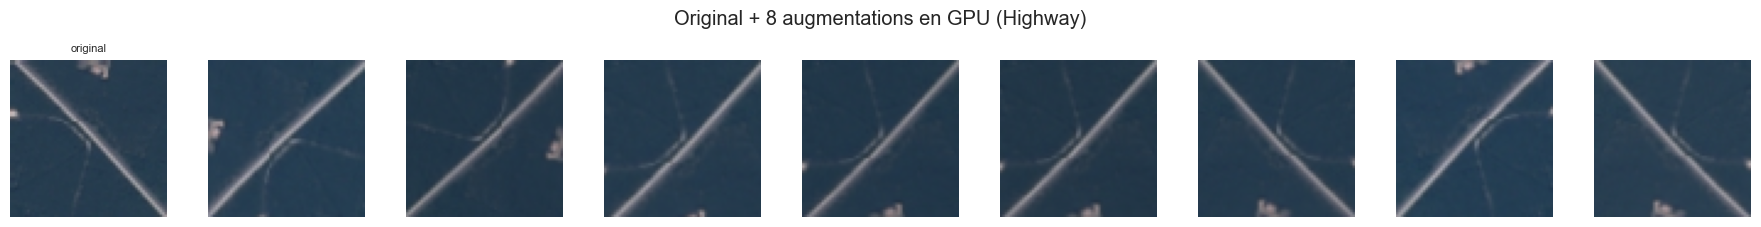

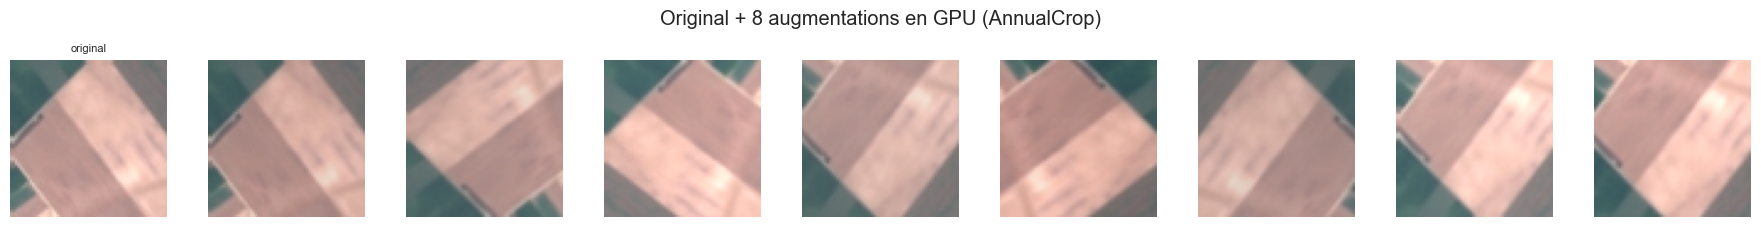

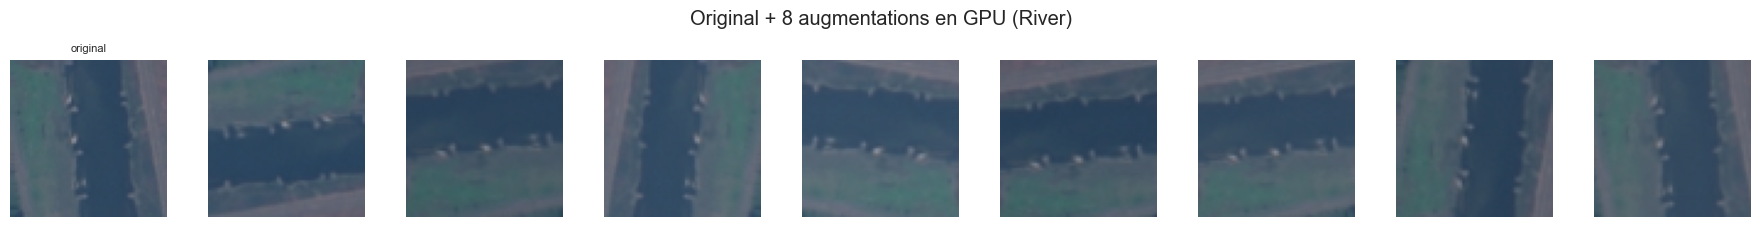

In [10]:
# 8 augmentations (hechas en GPU) de una misma imagen por clase
for c in ["Highway", "AnnualCrop", "River"]:
    idx = int(np.where(splits["train"]["class_name"] == c)[0][0])
    x8 = tensors["train"][0][idx:idx + 1].repeat(8, 1, 1, 1).to(DEVICE).float() / 255
    aug = data.gpu_augment(x8).cpu()
    fig, axes = plt.subplots(1, 9, figsize=(18, 2.3))
    axes[0].imshow(x8[0].cpu().permute(1, 2, 0)); axes[0].set_title("original", fontsize=8)
    for k in range(8):
        axes[k + 1].imshow(aug[k].permute(1, 2, 0))
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"Original + 8 augmentations en GPU ({c})")
    plt.tight_layout(); savefig(fig, f"augment_{c}"); plt.show()

## 4. Arquitectura custom (CNN desde cero)

Diseñamos una CNN compacta estilo VGG (`models.EuroSATCNN`):

```
Input 3×64×64
 ├─ ConvBlock(3→32)    : [Conv3×3-BN-ReLU]×2 + MaxPool → 32×32×32
 ├─ ConvBlock(32→64)   : [Conv3×3-BN-ReLU]×2 + MaxPool → 64×16×16
 ├─ ConvBlock(64→128)  : [Conv3×3-BN-ReLU]×2 + MaxPool + Dropout2d → 128×8×8
 ├─ ConvBlock(128→256) : [Conv3×3-BN-ReLU]×2 + MaxPool + Dropout2d → 256×4×4
 ├─ Global Average Pooling → 256
 ├─ Dropout → Linear(256→128) → ReLU → Dropout     ← espacio latente (128-d)
 └─ Linear(128→10)                                  ← capa de clasificación
```

Decisiones de diseño:

- **Kernels 3×3 apilados**: dos convoluciones 3×3 tienen el mismo campo
  receptivo que una 5×5 con menos parámetros y una no-linealidad extra. Al
  final de la red el campo receptivo cubre todo el recorte de 64×64.
- **Duplicar canales al reducir la resolución a la mitad**: mantiene
  aproximadamente constante el costo por bloque y permite aprender cada vez
  más patrones (bordes → texturas → parcelas/estructuras).
- **Batch Normalization** después de cada convolución: estabiliza la
  distribución de las activaciones y la escala de los gradientes; es la
  principal defensa contra vanishing/exploding gradients (lo verificamos en
  la sección 5.2) y permite usar learning rates más altos.
- **Inicialización de He (Kaiming)**: diseñada para ReLU, preserva la
  varianza de activaciones y gradientes entre capas al inicio del
  entrenamiento.
- **Global Average Pooling** en lugar de `Flatten`: la clase de un recorte de
  EuroSAT depende de su textura global más que de la posición exacta de los
  objetos; GAP aporta esa invarianza y reduce mucho los parámetros de la
  parte densa (256×128 en vez de 4096×128).
- **Dropout** (en el bloque denso y `Dropout2d` en los últimos bloques
  convolucionales): regularización, el dataset (~19k imágenes de train) es
  chico para entrenar desde cero.

In [11]:
set_seed(RANDOM_STATE)
custom_model = EuroSATCNN().to(DEVICE)
print(custom_model)
print("\nParámetros:", count_params(custom_model))

with torch.no_grad():
    out = custom_model(xb[:4].to(DEVICE))
    emb = custom_model.forward_features(xb[:4].to(DEVICE))
print("Logits:", tuple(out.shape), "| Embedding latente:", tuple(emb.shape))

EuroSATCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Identity()
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1),

## 5. Entrenamiento desde cero

- **Loss:** Cross-Entropy con *label smoothing* 0,1 (el target pasa de
  1 a 0,91 para la clase correcta, el resto se reparte entre las demás):
  desalienta la sobreconfianza y regulariza. Por eso la loss no puede bajar
  de ~0,5 aunque la red acierte todo.
- **Optimizador:** AdamW (`lr=1e-3`, `weight_decay=5e-4`): Adam con weight
  decay desacoplado, buena opción por defecto para CNNs desde cero.
- **Scheduler:** `OneCycleLR` (warm-up y luego decaimiento coseno, se
  actualiza en cada batch): acelera la convergencia y ayuda a terminar en un
  mínimo más "plano".
- **Épocas:** 60. En la primera versión (30 épocas) train y validación
  terminaban pegadas, sin overfitting: había margen para entrenar más.
- **Eficiencia:** precisión mixta `bfloat16` (`torch.autocast`) y formato
  `channels_last`, que aprovechan los Tensor Cores de la GPU. `bfloat16`
  tiene el mismo rango que `float32`, así que no necesita `GradScaler` y el
  monitor de gradientes ve los gradientes reales.
- **Selección del modelo:** guardamos los pesos de la época con mejor
  **accuracy de validación** (`fit` hace el *checkpointing* en memoria). El
  test solo se usa una vez, al final.
- **Monitoreo de gradientes:** `GradientMonitor` registra la norma L2 del
  gradiente de cada capa (conv/linear) cada 10 batches durante las primeras
  épocas.

### 5.1 Loop de entrenamiento

In [12]:
set_seed(RANDOM_STATE)
custom_model = EuroSATCNN().to(DEVICE)
optimizer = torch.optim.AdamW(custom_model.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-3, epochs=EPOCHS_CUSTOM,
    steps_per_epoch=len(loaders["train"]), pct_start=0.2,
)
grad_monitor = GradientMonitor(custom_model, max_epochs=GRAD_MONITOR_EPOCHS,
                               log_every=1 if SMOKE_TEST else 10)

hist_custom, _ = fit(
    custom_model, loaders, optimizer, DEVICE, epochs=EPOCHS_CUSTOM,
    scheduler=scheduler, grad_monitor=grad_monitor, name="CNN custom",
    criterion=nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING),
    amp=USE_AMP, channels_last=USE_AMP,
)
torch.save(custom_model.state_dict(), config.MODELS_DIR / "cnn_custom_best.pt")
hist_custom.to_csv(config.OUTPUTS_DIR / "history_cnn_custom.csv", index=False)

[CNN custom] epoch  1/60 | train loss 1.6240 acc 0.5277 | val loss 1.1531 acc 0.7257 | lr 1.69e-04 | 20.2s
[CNN custom] epoch  2/60 | train loss 1.2324 acc 0.6943 | val loss 1.0454 acc 0.7630 | lr 3.13e-04 | 3.8s
[CNN custom] epoch  3/60 | train loss 1.1348 acc 0.7425 | val loss 1.1943 acc 0.6944 | lr 5.42e-04 | 3.7s
[CNN custom] epoch  4/60 | train loss 1.0669 acc 0.7773 | val loss 0.9700 acc 0.8091 | lr 8.41e-04 | 3.7s
[CNN custom] epoch  5/60 | train loss 1.0216 acc 0.8010 | val loss 1.1021 acc 0.7822 | lr 1.19e-03 | 3.6s
[CNN custom] epoch  6/60 | train loss 0.9605 acc 0.8264 | val loss 1.1850 acc 0.7157 | lr 1.56e-03 | 3.7s
[CNN custom] epoch  7/60 | train loss 0.9060 acc 0.8501 | val loss 0.9360 acc 0.8285 | lr 1.93e-03 | 3.7s
[CNN custom] epoch  8/60 | train loss 0.8588 acc 0.8669 | val loss 0.8788 acc 0.8226 | lr 2.28e-03 | 3.7s
[CNN custom] epoch  9/60 | train loss 0.8389 acc 0.8742 | val loss 0.9926 acc 0.7881 | lr 2.58e-03 | 3.7s
[CNN custom] epoch 10/60 | train loss 0.8095 

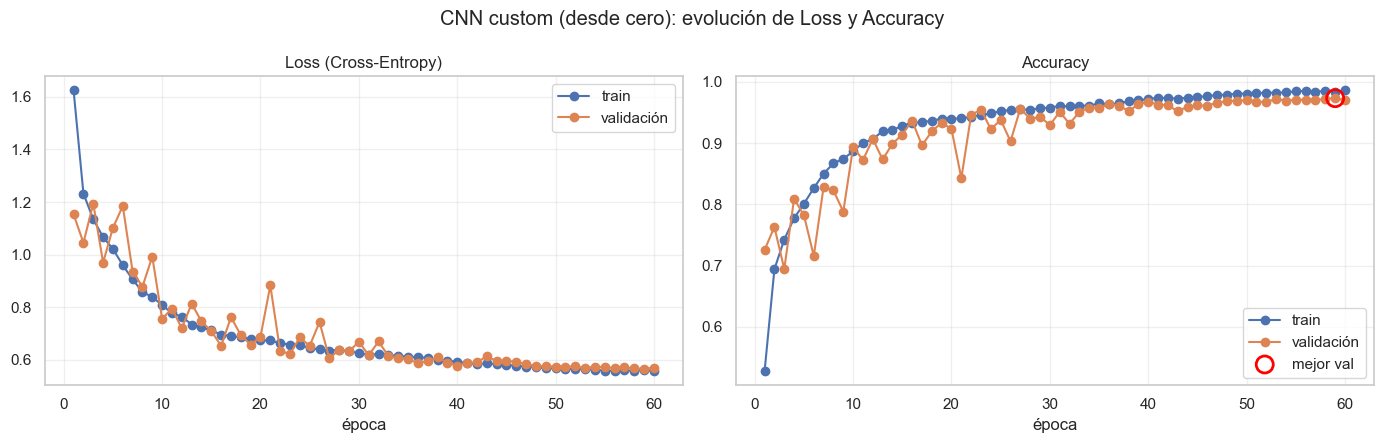

,epoch,train_loss,train_acc,val_loss,val_acc,lr,train_time_s,epoch_time_s,elapsed_s
55,56,0.5597,0.9850,0.5694,0.9709,0.0001,3.4752,3.7512,224.4981
56,57,0.5607,0.9838,0.5719,0.9704,0.0000,3.4568,3.7337,228.2321
57,58,0.5589,0.9849,0.5687,0.9719,0.0000,3.4723,3.7552,231.9875
58,59,0.5623,0.9836,0.5658,0.9731,0.0000,3.5239,3.8026,235.7904
59,60,0.5574,0.9858,0.5710,0.9700,0.0000,3.4814,3.7560,239.5506


In [13]:
fig = plot_history(hist_custom, "CNN custom (desde cero): evolución de Loss y Accuracy")
savefig(fig, "curvas_cnn_custom"); plt.show()
hist_custom.tail()

**Análisis de las curvas:**

- **Convergencia:** la CNN parte de 72,6% de validación en la época 1,
  supera el **90% en la época 12** y el **95% en la 23**. La mejor accuracy
  de validación es **97,31%** (época 59).
- **Oscilaciones mientras el LR es alto:** hasta la época ~30 la validación
  oscila bastante (por ejemplo, cae a 84% en la época 21). `OneCycleLR`
  sube el learning rate hasta 3e-3 en la época 12 y lo mantiene alto
  varias épocas: con pasos grandes los pesos saltan entre zonas del espacio
  de parámetros, y las estadísticas móviles de BatchNorm que se usan en
  `eval` quedan desactualizadas. Cuando el LR decae, las curvas convergen
  suavemente y la brecha desaparece.
- **Escala de la loss:** con *label smoothing* 0,1 el target ya no es un
  one-hot, así que la loss no puede bajar de ~0,5 aunque la red acierte
  todo. Por eso los valores (~0,56-0,57 al final) no son comparables con
  los de una Cross-Entropy común.
- **Sin overfitting:** al final train y validación quedan muy cerca, en loss
  (0,557 vs 0,571) y en accuracy (98,6% vs 97,0%). Duplicar las épocas
  (30 → 60) respecto de la primera versión fue útil: la accuracy de
  validación siguió subiendo hasta el final del entrenamiento.
- **Velocidad:** cada época tarda ~3,7 s (3,4 s de entrenamiento), contra
  ~12 s con el `DataLoader` en CPU. La primera época tarda más (20 s)
  porque cuDNN prueba distintos algoritmos de convolución (`benchmark`).

### 5.2 Monitoreo del flujo de gradientes

Para cada capa con pesos (convoluciones y lineales, ordenadas de la entrada a
la salida) graficamos:

1. la norma del gradiente a lo largo de los batches de las primeras épocas,
2. la norma media por capa (con su rango min-max),
3. la norma global del gradiente.

**¿Qué buscamos?**

- **Vanishing gradients:** las primeras capas con normas **órdenes de
  magnitud** menores que las últimas (o tendiendo a 0) → no aprenden.
- **Exploding gradients:** normas que crecen sin control, picos enormes o
  `NaN`/`Inf` → la loss diverge.
- **Flujo sano:** normas del mismo orden de magnitud entre capas (diferencias
  de 1-2 órdenes son normales), estables o decreciendo suavemente a medida
  que la loss baja.

c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4480\1347394864.py:18: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4480\1347394864.py:18: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8711 (\N{NABLA}) missing 

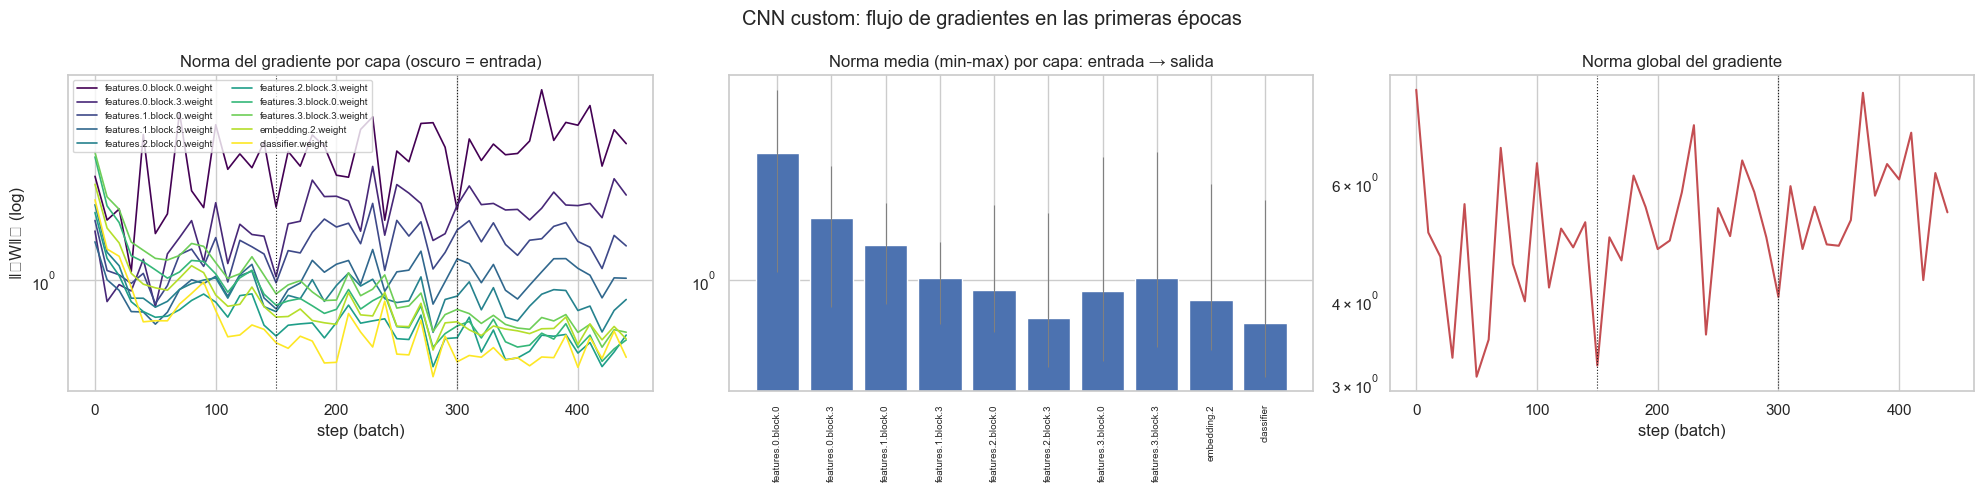

,grad_norm_mean,grad_norm_min,grad_norm_max,grad_to_weight_mean
layer,,,,
features.0.block.0.weight,3.8579,1.0956,7.5268,1.5756
features.0.block.3.weight,1.9394,0.7553,3.3430,0.2404
features.1.block.0.weight,1.4572,0.7823,2.2599,0.1821
features.1.block.3.weight,1.0213,0.6294,1.5045,0.0903
features.2.block.0.weight,0.9001,0.5772,2.2273,0.0794
features.2.block.3.weight,0.6721,0.4010,2.0508,0.0419
features.3.block.0.weight,0.8911,0.4245,3.6937,0.0556
features.3.block.3.weight,1.0229,0.4930,3.8742,0.0451
embedding.2.weight,0.8084,0.4784,2.7658,0.0509


hay_nan_o_inf                                           False
capas_con_grad_casi_nulo (<1e-06)                          []
max_norma_registrada                                   7.5268
explosion (>100)                                        False
ratio_max/min_entre_capas                              6.0857
desbalance_fuerte (>1000)                               False
norma_media_primera_capa (features.0.block.0.weight)   3.8579
norma_media_ultima_capa (classifier.weight)            0.6339
Name: diagnóstico, dtype: object

In [14]:
fig = grad_monitor.plot("CNN custom: flujo de gradientes en las primeras épocas")
savefig(fig, "gradientes_cnn_custom"); plt.show()

display(grad_monitor.summary())
pd.Series(grad_monitor.diagnose(), name="diagnóstico")

**Contraste didáctico (opcional): qué pasaría sin BatchNorm ni ReLU.**
Para poner en contexto los números de arriba, entrenamos unos pocos batches
de una CNN **profunda (10 convs), sin BatchNorm y con activación sigmoide**
—la receta clásica del vanishing gradient: la derivada de la sigmoide es como
mucho 0.25, así que el gradiente se multiplica por factores < 1 en cada capa
al hacer backpropagation—. Si el diagnóstico es correcto, en esta red las
primeras capas deberían recibir gradientes varios órdenes de magnitud más
chicos que la última.

c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4480\1347394864.py:18: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4480\1347394864.py:18: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8711 (\N{NABLA}) missing 

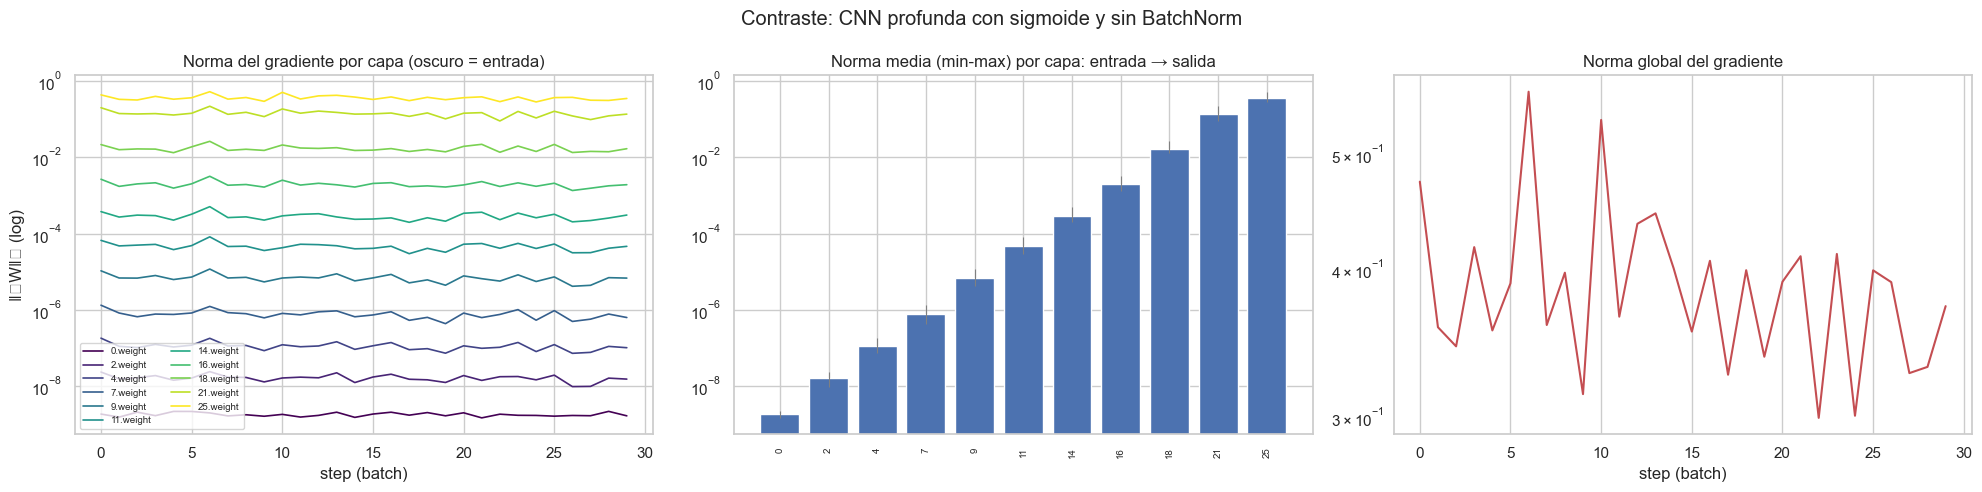

,primera capa,última capa,ratio última/primera
CNN custom (BN+ReLU),3.86e+00,6.34e-01,1.64e-01
CNN sigmoide sin BN,1.82e-09,3.60e-01,1.98e+08


In [15]:
RUN_GRADIENT_CONTRAST = True

if RUN_GRADIENT_CONTRAST:
    def plain_sigmoid_cnn(depth=10, ch=32):
        layers, in_ch = [], 3
        for i in range(depth):
            layers += [nn.Conv2d(in_ch, ch, 3, padding=1), nn.Sigmoid()]
            if i % 3 == 2:
                layers.append(nn.MaxPool2d(2))
            in_ch = ch
        return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                             nn.Linear(ch, config.NUM_CLASSES))

    set_seed(RANDOM_STATE)
    bad_model = plain_sigmoid_cnn().to(DEVICE)
    bad_monitor = GradientMonitor(bad_model, max_epochs=1, log_every=1)
    bad_opt = torch.optim.SGD(bad_model.parameters(), lr=0.01)
    crit = nn.CrossEntropyLoss()
    bad_model.train()
    for step, (x, y) in enumerate(loaders["train"]):
        if step >= 30:
            break
        bad_opt.zero_grad()
        crit(bad_model(x.to(DEVICE)), y.to(DEVICE)).backward()
        bad_monitor.log(epoch=0)
        bad_opt.step()

    fig = bad_monitor.plot("Contraste: CNN profunda con sigmoide y sin BatchNorm")
    savefig(fig, "gradientes_contraste_sigmoide"); plt.show()

    cmp = pd.DataFrame({
        "CNN custom (BN+ReLU)": grad_monitor.summary()["grad_norm_mean"].values[[0, -1]],
        "CNN sigmoide sin BN": bad_monitor.summary()["grad_norm_mean"].values[[0, -1]],
    }, index=["primera capa", "última capa"]).T
    cmp["ratio última/primera"] = cmp["última capa"] / cmp["primera capa"]
    display(cmp.style.format("{:.2e}"))

**Conclusión sobre gradientes:**

- **No hay vanishing gradients:** todas las capas reciben gradientes del
  mismo orden de magnitud. La norma media va de 3,86 en la primera
  convolución a 0,63 en la capa de clasificación, y el cociente entre la
  capa con más y la capa con menos gradiente es **6,1**, menos de un orden
  de magnitud. Ninguna capa queda con gradiente casi nulo, y es justamente
  la **primera** capa la que recibe el gradiente más grande, lo opuesto al
  patrón de vanishing.
- **No hay exploding gradients:** no aparecen `NaN` ni `Inf`, y la norma
  máxima registrada en una capa fue 7,5. La norma global tiene picos
  moderados durante el *warm-up* del learning rate y vuelve enseguida a su
  nivel; la loss nunca diverge.
- **Contraste con la red patológica:** en la CNN de 10 convoluciones con
  sigmoide y sin BatchNorm, la primera capa recibe un gradiente de
  **1,8·10⁻⁹** contra **0,36** en la última: un cociente de **~2·10⁸**.
  Cada capa achica el gradiente casi un orden de magnitud (la derivada de
  la sigmoide vale como máximo 0,25), así que las primeras capas
  prácticamente no aprenden. Ese es el vanishing gradient clásico.
- **Por qué nuestra CNN no lo sufre:**
  1. **ReLU** tiene derivada 1 en la zona activa, así que no achica el
     gradiente en cada capa.
  2. **BatchNorm** re-normaliza las activaciones en cada capa y mantiene
     estable su escala, y con ella la del gradiente.
  3. La **inicialización de He** arranca con varianzas adecuadas para ReLU.
  4. La red es poco profunda: 10 capas con pesos.
- **Con precisión mixta:** al usar `bfloat16`, que tiene el mismo rango que
  `float32`, no hace falta escalar la loss, y las normas medidas son las
  reales.
- **ResNet18:** el monitor muestra lo mismo (cociente 5,2; 1,15 en `conv1`
  vs 1,70 en `fc`), gracias además a las *skip connections*.

## 6. Evaluación en test y análisis de errores

Evaluamos **una única vez** el mejor modelo (según validación) sobre el
conjunto de test, sin y con **Test-Time Augmentation (TTA)**: como la clase
de una imagen cenital no depende de su orientación, promediamos las
probabilidades de las 8 orientaciones (4 rotaciones × con/sin flip) de cada
imagen. Es otra forma de explotar la misma invarianza que usamos en el
entrenamiento, sin costo de entrenamiento extra. El análisis de errores se
hace sobre las predicciones con TTA.

In [16]:
# Sin y con Test-Time Augmentation (promedio de las 8 orientaciones)
_, y_pred_plain, _ = predict(custom_model, loaders["test"], DEVICE)
y_true_c, y_pred_c, probs_c = predict(custom_model, loaders["test"], DEVICE, tta=True)
test_custom = metrics_summary(y_true_c, y_pred_c)
test_custom_plain = metrics_summary(y_true_c, y_pred_plain)
print("CNN custom - test sin TTA:", {k: round(v, 4) for k, v in test_custom_plain.items()})
print("CNN custom - test con TTA:", {k: round(v, 4) for k, v in test_custom.items()})
report_df(y_true_c, y_pred_c)

CNN custom - test sin TTA: {'accuracy': 0.9785, 'f1_macro': 0.9781, 'f1_weighted': 0.9786}
CNN custom - test con TTA: {'accuracy': 0.9781, 'f1_macro': 0.9777, 'f1_weighted': 0.9782}


,precision,recall,f1-score,support
AnnualCrop,0.9831,0.9700,0.9765,300.0000
Forest,0.9771,0.9967,0.9868,300.0000
HerbaceousVegetation,0.9827,0.9467,0.9643,300.0000
Highway,0.9841,0.9880,0.9860,250.0000
Industrial,0.9959,0.9680,0.9817,250.0000
Pasture,0.9896,0.9550,0.9720,200.0000
PermanentCrop,0.9071,0.9760,0.9403,250.0000
Residential,0.9772,1.0000,0.9885,300.0000
River,0.9880,0.9840,0.9860,250.0000
SeaLake,1.0000,0.9900,0.9950,300.0000


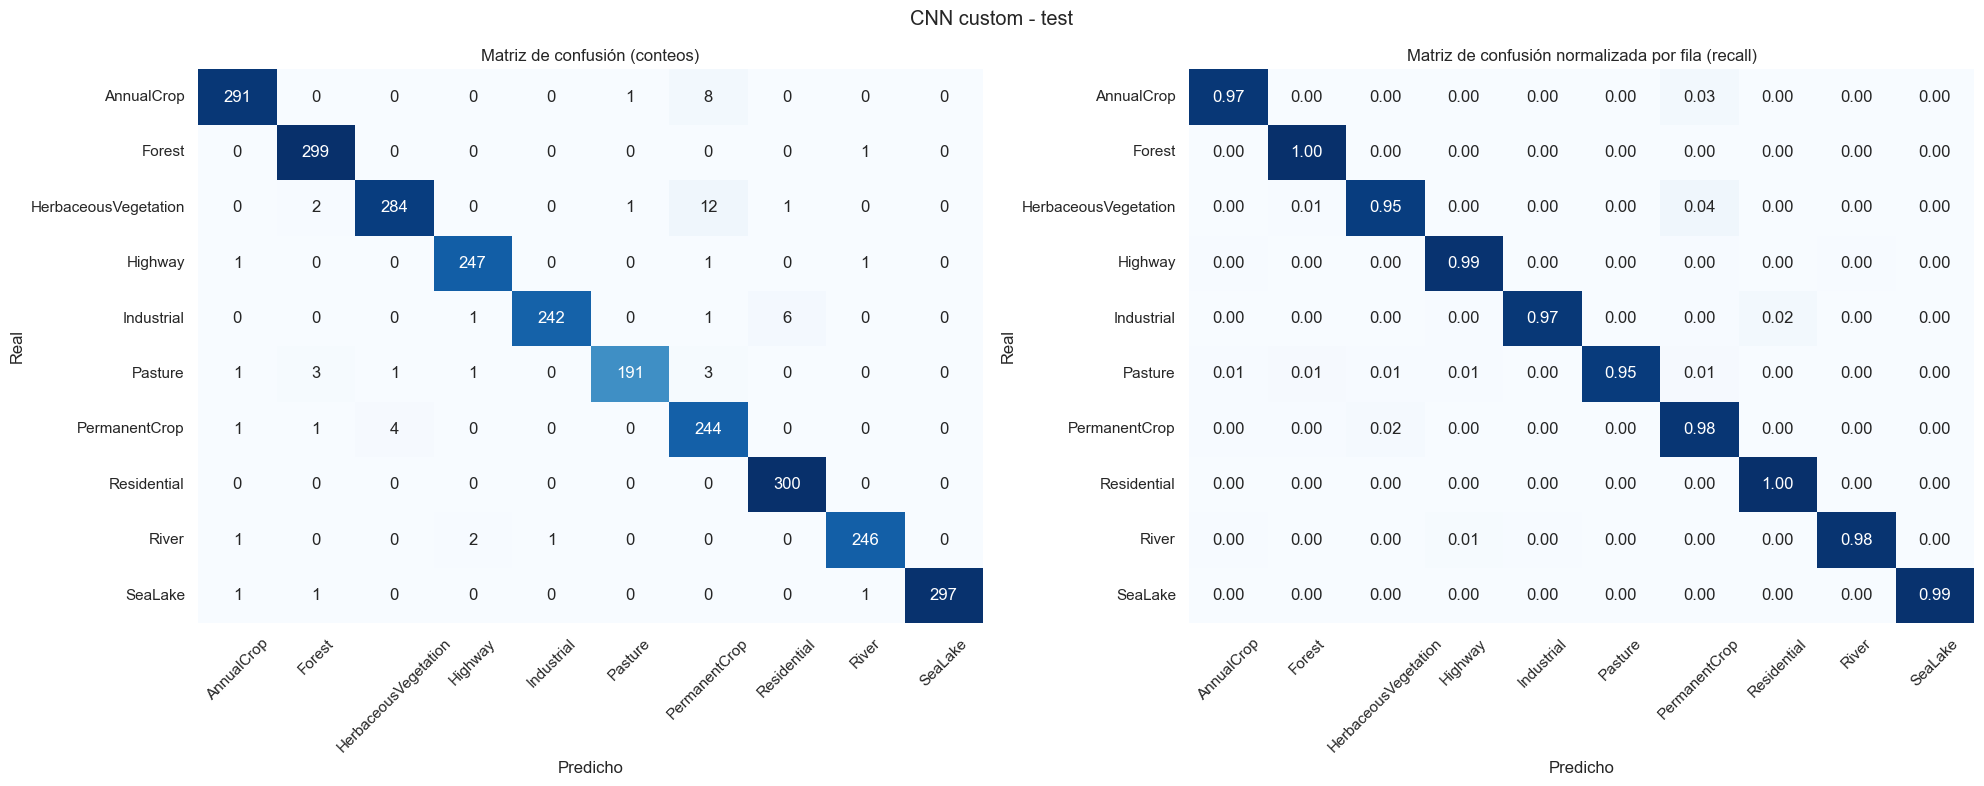

,real,predicho,n_errores,pct_de_la_clase_real
0,HerbaceousVegetation,PermanentCrop,12,0.0400
1,AnnualCrop,PermanentCrop,8,0.0267
2,Industrial,Residential,6,0.0240
3,PermanentCrop,HerbaceousVegetation,4,0.0160
4,Pasture,PermanentCrop,3,0.0150
5,Pasture,Forest,3,0.0150
6,River,Highway,2,0.0080
7,HerbaceousVegetation,Forest,2,0.0067


In [17]:
fig, cm_custom = plot_confusion_matrix(y_true_c, y_pred_c, title="CNN custom - test")
savefig(fig, "confusion_cnn_custom"); plt.show()

conf_custom = top_confusions(cm_custom, k=8)
conf_custom

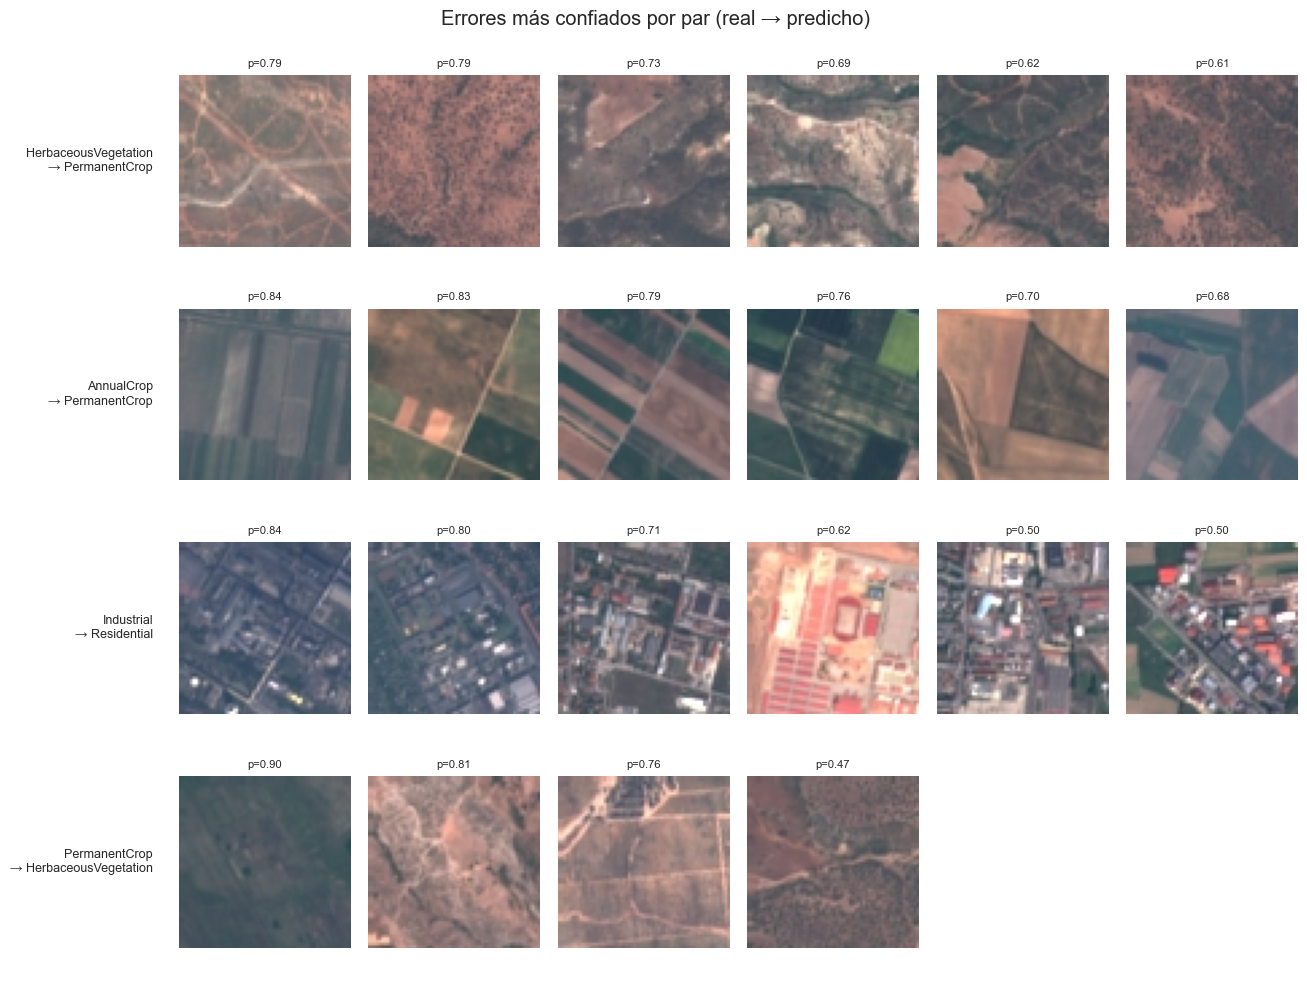

In [18]:
test_ds_vis = data.EuroSATDataset(splits["test"], eval_tf)
pairs = list(conf_custom[["real", "predicho"]].head(4).itertuples(index=False, name=None))
fig = plot_misclassified(test_ds_vis, y_true_c, y_pred_c, probs_c,
                         EUROSAT_MEAN, EUROSAT_STD, pairs=pairs, n_per_pair=6)
if fig is not None:
    savefig(fig, "errores_cnn_custom"); plt.show()

**Análisis de las confusiones más frecuentes:**

La CNN custom logra **97,85% de accuracy sin TTA y 97,81% con TTA** (F1
macro 0,978). Comete 59 errores sobre 2.700 imágenes, contra 83 en la
primera versión, y se concentran en pocos pares:

| Real → Predicho | Errores | % de la clase real |
|---|---|---|
| `HerbaceousVegetation` → `PermanentCrop` | 12 | 4,0% |
| `AnnualCrop` → `PermanentCrop` | 8 | 2,7% |
| `Industrial` → `Residential` | 6 | 2,4% |
| `PermanentCrop` → `HerbaceousVegetation` | 4 | 1,6% |
| `Pasture` → `PermanentCrop` | 3 | 1,5% |
| `Pasture` → `Forest` | 3 | 1,5% |

- **El grupo vegetal sigue siendo la principal fuente de error.**
  `PermanentCrop` es la clase con peor F1 (0,940): tiene recall alto
  (97,6%) pero precisión baja (90,7%). Funciona como "clase sumidero": la
  red la predice ante las dudas entre coberturas vegetales, y 3 de los 6
  pares más confundidos terminan en ella. En la primera versión el
  sumidero era `HerbaceousVegetation` (14 errores
  `PermanentCrop` → `HerbaceousVegetation`); ahora la confusión se invirtió,
  pero el par sigue siendo el mismo. Esto confirma que la frontera entre
  esas clases es genuinamente ambigua.
- **Mirando los errores:** las `HerbaceousVegetation` predichas como
  `PermanentCrop` son zonas **secas, de vegetación rala**, con caminos o
  senderos lineales que imitan las filas de una plantación. Los
  `AnnualCrop` predichos como `PermanentCrop` son parcelas con **surcos
  paralelos**, la textura típica de viñedos y frutales. Distinguir un
  cultivo anual de uno permanente es en el fondo una cuestión **temporal**
  (fenología), información que una sola imagen RGB no tiene.
- **`Industrial` → `Residential` (6 errores):** zonas urbanas densas con
  edificios chicos, o mezcla de usos (por ejemplo, un predio deportivo con
  galpones). A 10 m/píxel no se distingue el uso del edificio, y
  `Residential` tiene **recall 1,00**: absorbe los casos urbanos dudosos.
- **`Highway` ↔ `River` casi no se confunden** (2 errores): el color
  resuelve la ambigüedad de forma, porque el agua es más oscura y azulada
  que el asfalto.
- **Clases más fáciles:** `SeaLake` (F1 0,995), `Residential` (0,989),
  `Forest` (0,987), `Highway` y `River` (0,986).
- **TTA no cambia nada en este modelo** (−1 imagen): la CNN custom ya
  aprendió la invarianza a la orientación durante 60 épocas de
  augmentation, así que sus predicciones son prácticamente iguales en las
  8 orientaciones.
- Los errores ocurren entre clases **visual y semánticamente vecinas**,
  casi nunca entre grupos dispares. Varios se ven ambiguos incluso a
  simple vista y podrían ser recortes mixtos o ruido de etiquetado.

## 7. Espacio latente

Extraemos los features **justo antes de la capa de clasificación final**
(input de la última `nn.Linear`, capturado con un *forward hook*): para la
CNN custom es el embedding de **128 dimensiones**. Lo proyectamos a 2D con:

- **PCA**: proyección lineal; muestra la estructura global, pero no puede
  "desenrollar" variedades no lineales.
- **t-SNE**: preserva vecindarios locales (buena para ver clusters), pero las
  distancias entre clusters y su tamaño **no** son interpretables.
- **UMAP**: también no lineal, más rápido que t-SNE y suele preservar mejor
  la estructura global.

Como cuantificación complementaria calculamos el **silhouette score**
usando las clases reales como clusters (≈1: clusters compactos y separados;
≈0: solapados). Como **baseline** proyectamos también los **píxeles
crudos**: así vemos cuánto de la separabilidad la "construye" la red.

Features latentes (test): (2700, 128)


C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Proyecciones calculadas en 27.2s


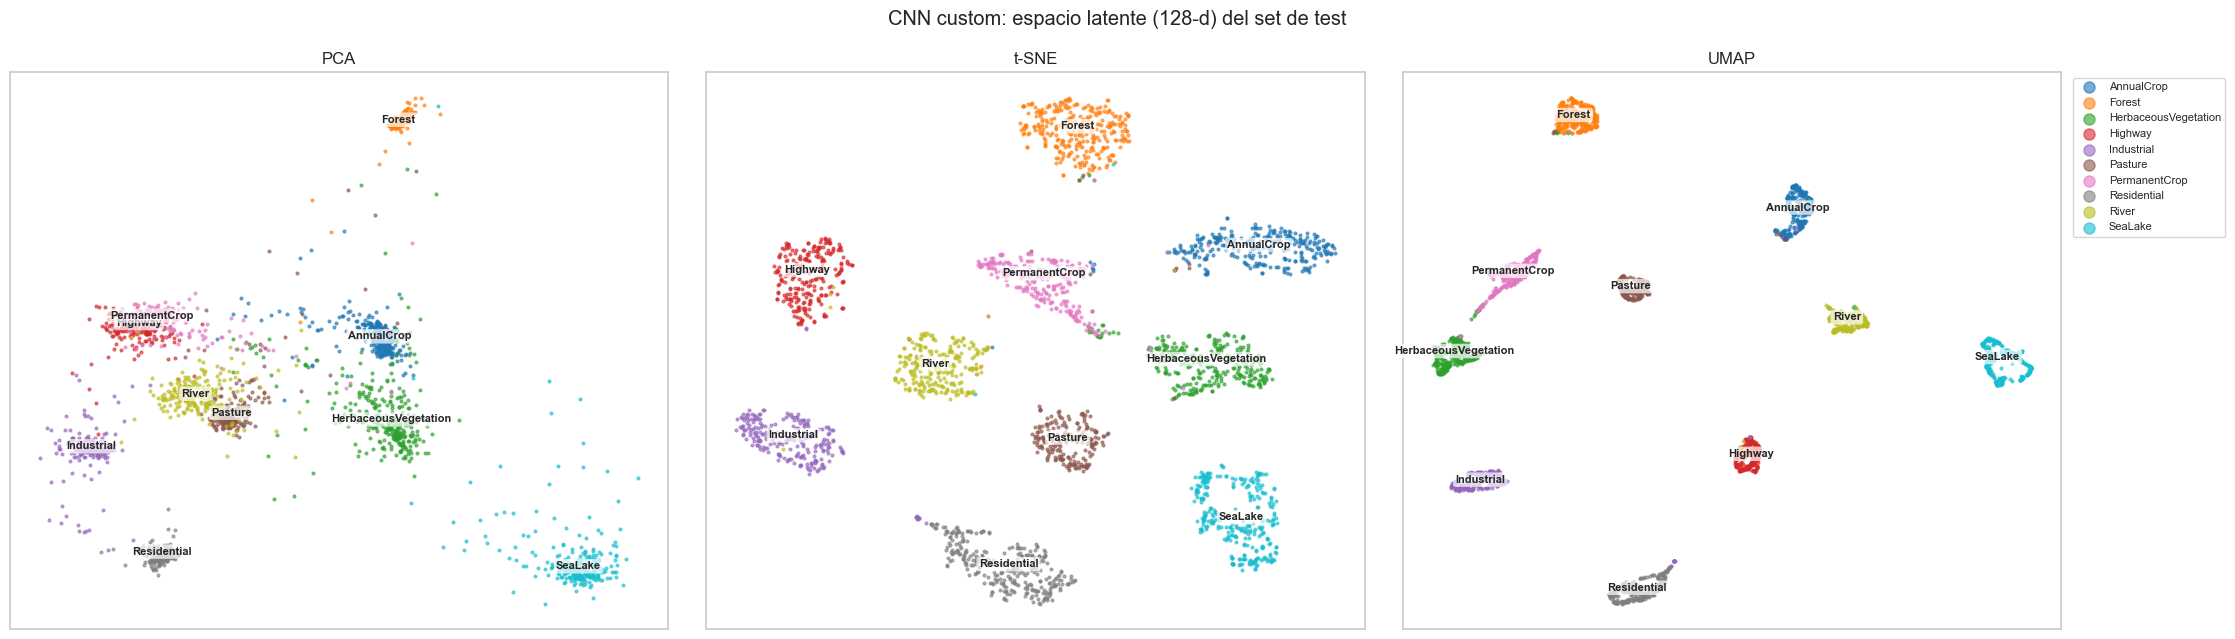

In [19]:
feats_c, labels_c = extract_features(custom_model, loaders["test"], DEVICE)
print("Features latentes (test):", feats_c.shape)

t0 = time.perf_counter()
emb_custom = {
    "PCA": project(feats_c, "pca"),
    "t-SNE": project(feats_c, "tsne"),
    "UMAP": project(feats_c, "umap"),
}
print(f"Proyecciones calculadas en {time.perf_counter() - t0:.1f}s")

fig = plot_embeddings(emb_custom, labels_c, title="CNN custom: espacio latente (128-d) del set de test")
savefig(fig, "latente_cnn_custom"); plt.show()

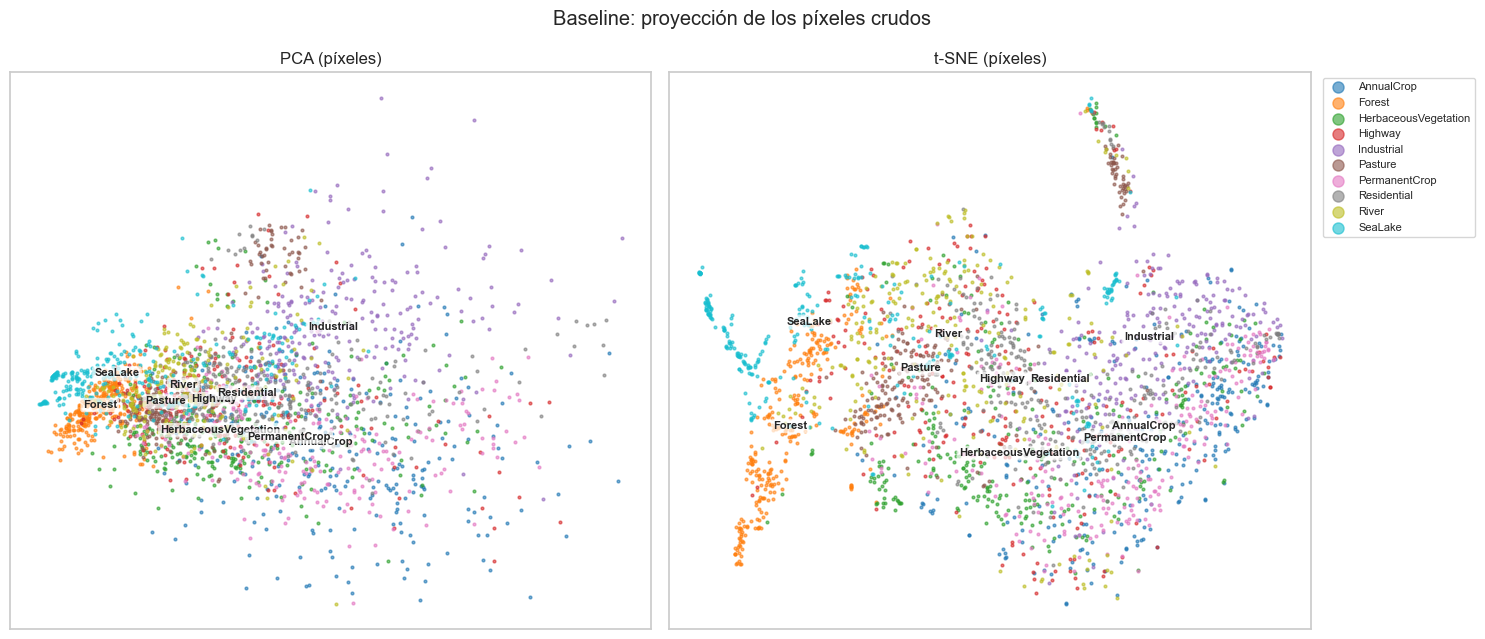

,espacio,silhouette
0,latente (128-d),0.7150
1,PCA 2D (latente),0.5278
2,t-SNE 2D (latente),0.6568
3,UMAP 2D (latente),0.7834
4,píxeles crudos (12288-d),-0.1079
5,t-SNE 2D (píxeles),-0.1406


In [20]:
# Baseline: los mismos métodos sobre los píxeles crudos (3x64x64 = 12288-d)
X_raw, y_raw = raw_pixels(loaders["test"])
emb_raw = {"PCA (píxeles)": project(X_raw, "pca"), "t-SNE (píxeles)": project(X_raw, "tsne")}
fig = plot_embeddings(emb_raw, y_raw, title="Baseline: proyección de los píxeles crudos")
savefig(fig, "latente_pixeles"); plt.show()

sep = pd.concat([
    separability_scores(feats_c, labels_c, {f"{k} 2D (latente)": v for k, v in emb_custom.items()}),
    separability_scores(X_raw, y_raw, {"t-SNE 2D (píxeles)": emb_raw["t-SNE (píxeles)"]})
        .replace({"espacio": {f"latente ({X_raw.shape[1]}-d)": f"píxeles crudos ({X_raw.shape[1]}-d)"}}),
], ignore_index=True)
sep

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


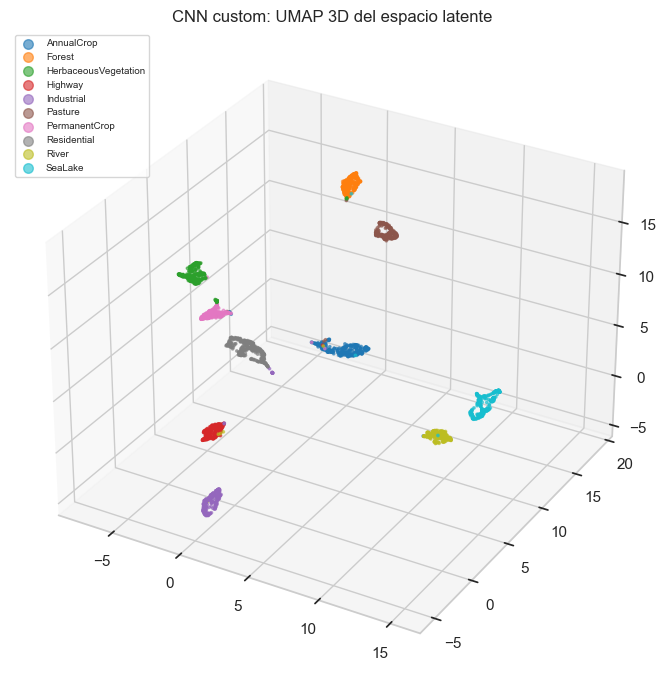

In [21]:
# Vista 3D (UMAP con 3 componentes)
emb3d = project(feats_c, "umap", n_components=3)
fig = plot_embedding_3d(emb3d, labels_c, title="CNN custom: UMAP 3D del espacio latente")
savefig(fig, "latente_cnn_custom_3d"); plt.show()

**Análisis del espacio latente:**

- **Las clases forman clusters claramente distinguibles antes de la capa
  final.** En t-SNE y UMAP aparecen 10 grupos compactos y separados, uno
  por clase. El silhouette es **0,72 en el espacio latente de 128
  dimensiones**, 0,66 en t-SNE y 0,78 en UMAP. Como la capa final es un
  clasificador lineal sobre este embedding, una separación así explica la
  alta accuracy.
- **Mejora respecto de la primera versión:** el silhouette en el espacio de
  128 dimensiones subió de 0,51 a **0,72**, y el de PCA 2D de 0,27 a 0,53.
  Es un efecto conocido del ***label smoothing***: al no premiar logits
  infinitamente confiados, empuja a que los ejemplos de una misma clase se
  agrupen de forma compacta y a igual distancia de las demás clases.
- **Los solapamientos coinciden con la matriz de confusión:** en t-SNE,
  `PermanentCrop` se estira hacia `HerbaceousVegetation` y `AnnualCrop`, con
  puntos sueltos en la frontera; en UMAP, `PermanentCrop` y
  `HerbaceousVegetation` son los dos clusters más cercanos. Son los pares
  más confundidos de la sección 6.
- **Estructura semántica:** en PCA, que preserva mejor la geometría global,
  las coberturas vegetales y las estructuras lineales (`River`, `Highway`,
  `Pasture`) quedan en el centro, mientras que `SeaLake`, `Forest`,
  `Residential` e `Industrial` se despegan en direcciones propias.
- **La red construye la separabilidad:** en los **píxeles crudos** el
  silhouette es **negativo** (−0,11 en el espacio original y −0,14 en
  t-SNE), es decir, las clases están completamente mezcladas. Las clases no
  son separables en el espacio de entrada; son las capas convolucionales las
  que llevan la imagen a una representación donde sí lo son.

## 8. Transfer Learning: ResNet18 preentrenada en ImageNet

Elegimos **ResNet18**: es una arquitectura clásica, liviana (11M de
parámetros) y con *skip connections*, que garantizan un buen flujo de
gradientes aunque descongelemos toda la red.

**Adaptación a EuroSAT:**

- Reemplazamos la capa final `fc` (1000 clases de ImageNet) por una
  `Linear(512 → 10)` inicializada al azar.
- Normalizamos con la **media/desvío de ImageNet** (son las estadísticas con
  las que fueron entrenados los filtros) y usamos la misma augmentation que
  en la CNN custom.
- Resolución: `TL_IMG_SIZE = 64` (nativa de EuroSAT) para que la
  comparación de convergencia y tiempo por época con la CNN custom sea
  justa.

**Tres variantes** (`build_resnet18(trainable=...)`):

1. **Solo últimas capas** (`trainable="layer4"`): congelamos todo el
   backbone salvo el último bloque residual y la cabeza. Se entrenan menos
   parámetros y cada época es más barata (no hay que calcular gradientes de
   las primeras capas).
2. **Fine-tuning completo** (`trainable="all"`) con **learning rates
   discriminativos**: `1e-4` para el backbone (ajustar sin destruir lo
   aprendido en ImageNet) y `1e-3` para la cabeza nueva.
3. **Fine-tuning completo a 224×224 (variante optimizada):** igual que la
   anterior, pero reescalando las imágenes (en GPU) a la resolución con la
   que se preentrenó ResNet18. A 64×64 la red reduce la imagen a un mapa de
   2×2 en `layer4`, mientras que a 224×224 trabaja con 7×7 y sus filtros
   ven los objetos a la escala para la que fueron entrenados. Cuesta ~12×
   más cómputo por imagen.

Las tres usan precisión mixta `bfloat16` y `channels_last`.

Hay un *domain shift* entre ImageNet (fotos de objetos tomadas de costado) y
EuroSAT (texturas cenitales), pero los filtros de las primeras capas (bordes,
colores, texturas) son genéricos y se transfieren bien.

In [22]:
tl_loaders = data.make_gpu_loaders(tensors, config.IMAGENET_MEAN, config.IMAGENET_STD, DEVICE,
                                   batch_size=BATCH_SIZE, img_size=TL_IMG_SIZE)
hires_loaders = data.make_gpu_loaders(tensors, config.IMAGENET_MEAN, config.IMAGENET_STD, DEVICE,
                                      batch_size=BATCH_SIZE, img_size=TL_HIRES_SIZE)


def train_resnet(trainable, name, loaders=tl_loaders, lr_backbone=1e-4, lr_head=1e-3, monitor=False):
    set_seed(RANDOM_STATE)
    model = build_resnet18(pretrained=PRETRAINED, trainable=trainable).to(DEVICE)
    print(f"{name} - parámetros:", count_params(model))
    groups = resnet_param_groups(model, lr_backbone=lr_backbone, lr_head=lr_head)
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=[g["lr"] for g in groups], epochs=EPOCHS_TL,
        steps_per_epoch=len(loaders["train"]), pct_start=0.2,
    )
    gm = GradientMonitor(model, max_epochs=GRAD_MONITOR_EPOCHS,
                         log_every=1 if SMOKE_TEST else 10) if monitor else None
    hist, _ = fit(model, loaders, opt, DEVICE, epochs=EPOCHS_TL,
                  scheduler=sched, grad_monitor=gm, name=name,
                  amp=USE_AMP, channels_last=USE_AMP)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    torch.save(model.state_dict(), config.MODELS_DIR / f"{name.replace(' ', '_')}.pt")
    hist.to_csv(config.OUTPUTS_DIR / f"history_{name.replace(' ', '_')}.csv", index=False)
    return model, hist, gm

### 8.1 ResNet18 descongelando solo `layer4` + `fc`

ResNet18 layer4+fc - parámetros: {'total': 11181642, 'trainable': 8398858}
[ResNet18 layer4+fc] epoch  1/10 | train loss 1.3586 acc 0.5769 | val loss 0.4493 acc 0.8620 | lr 5.23e-04 | 19.4s
[ResNet18 layer4+fc] epoch  2/10 | train loss 0.3180 acc 0.8959 | val loss 0.2578 acc 0.9141 | lr 1.00e-03 | 2.6s
[ResNet18 layer4+fc] epoch  3/10 | train loss 0.2208 acc 0.9243 | val loss 0.2303 acc 0.9224 | lr 9.61e-04 | 2.5s
[ResNet18 layer4+fc] epoch  4/10 | train loss 0.1727 acc 0.9393 | val loss 0.2023 acc 0.9319 | lr 8.53e-04 | 2.5s
[ResNet18 layer4+fc] epoch  5/10 | train loss 0.1500 acc 0.9483 | val loss 0.1887 acc 0.9391 | lr 6.90e-04 | 2.6s
[ResNet18 layer4+fc] epoch  6/10 | train loss 0.1343 acc 0.9535 | val loss 0.1833 acc 0.9404 | lr 4.99e-04 | 2.7s
[ResNet18 layer4+fc] epoch  7/10 | train loss 0.1086 acc 0.9622 | val loss 0.1778 acc 0.9422 | lr 3.07e-04 | 2.5s
[ResNet18 layer4+fc] epoch  8/10 | train loss 0.1035 acc 0.9634 | val loss 0.1727 acc 0.9409 | lr 1.46e-04 | 2.5s
[ResNet18 la

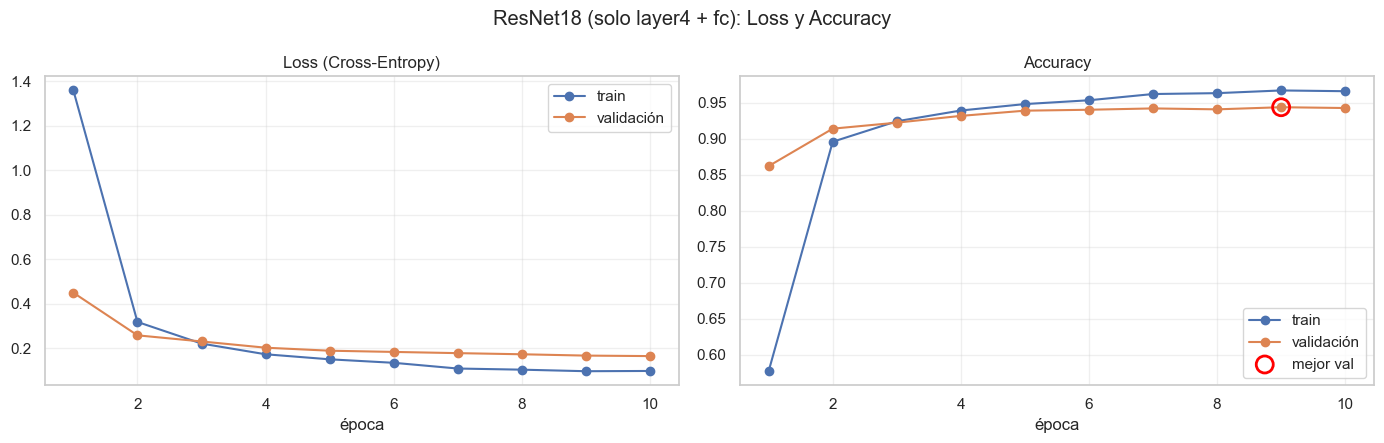

In [23]:
resnet_l4, hist_l4, _ = train_resnet("layer4", "ResNet18 layer4+fc")
fig = plot_history(hist_l4, "ResNet18 (solo layer4 + fc): Loss y Accuracy")
savefig(fig, "curvas_resnet_layer4"); plt.show()

### 8.2 ResNet18 con fine-tuning completo

ResNet18 fine-tuning - parámetros: {'total': 11181642, 'trainable': 11181642}
[ResNet18 fine-tuning] epoch  1/10 | train loss 1.2613 acc 0.6058 | val loss 0.3280 acc 0.8961 | lr 5.23e-04 | 10.4s
[ResNet18 fine-tuning] epoch  2/10 | train loss 0.2307 acc 0.9250 | val loss 0.1772 acc 0.9394 | lr 1.00e-03 | 3.9s
[ResNet18 fine-tuning] epoch  3/10 | train loss 0.1423 acc 0.9522 | val loss 0.1510 acc 0.9509 | lr 9.61e-04 | 4.1s
[ResNet18 fine-tuning] epoch  4/10 | train loss 0.1166 acc 0.9605 | val loss 0.1274 acc 0.9578 | lr 8.53e-04 | 3.9s
[ResNet18 fine-tuning] epoch  5/10 | train loss 0.0898 acc 0.9708 | val loss 0.1280 acc 0.9569 | lr 6.90e-04 | 3.7s
[ResNet18 fine-tuning] epoch  6/10 | train loss 0.0766 acc 0.9733 | val loss 0.1436 acc 0.9517 | lr 4.99e-04 | 3.4s
[ResNet18 fine-tuning] epoch  7/10 | train loss 0.0633 acc 0.9792 | val loss 0.1304 acc 0.9565 | lr 3.07e-04 | 3.3s
[ResNet18 fine-tuning] epoch  8/10 | train loss 0.0515 acc 0.9827 | val loss 0.1263 acc 0.9585 | lr 1.46e-04 

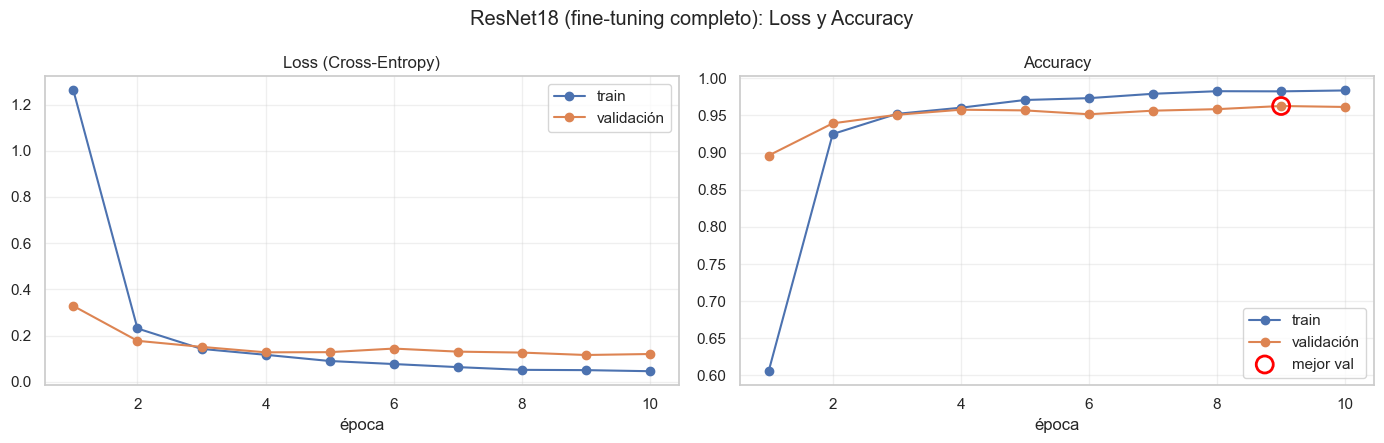

In [24]:
resnet_ft, hist_ft, gm_ft = train_resnet("all", "ResNet18 fine-tuning", monitor=True)
fig = plot_history(hist_ft, "ResNet18 (fine-tuning completo): Loss y Accuracy")
savefig(fig, "curvas_resnet_finetuning"); plt.show()

c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4480\1347394864.py:18: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_4480\1347394864.py:18: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8711 (\N{NABLA}) missing 

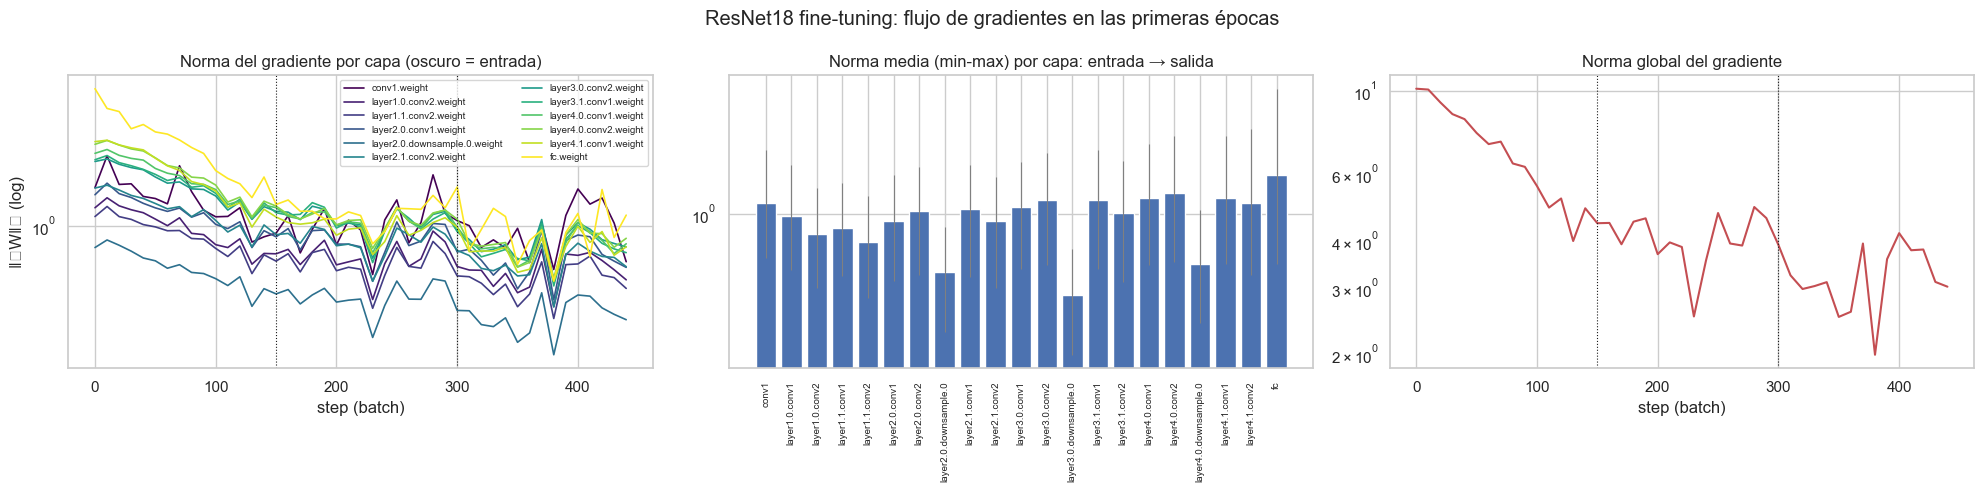

hay_nan_o_inf                              False
capas_con_grad_casi_nulo (<1e-06)             []
max_norma_registrada                      5.4984
explosion (>100)                           False
ratio_max/min_entre_capas                 5.1652
desbalance_fuerte (>1000)                  False
norma_media_primera_capa (conv1.weight)   1.1539
norma_media_ultima_capa (fc.weight)       1.6998
Name: diagnóstico, dtype: object

In [25]:
# Flujo de gradientes en el fine-tuning: las skip connections deberían
# mantener normas comparables entre las primeras y las últimas capas.
fig = gm_ft.plot("ResNet18 fine-tuning: flujo de gradientes en las primeras épocas")
savefig(fig, "gradientes_resnet_finetuning"); plt.show()
pd.Series(gm_ft.diagnose(), name="diagnóstico")

### 8.3 ResNet18 con fine-tuning completo a 224×224 (variante optimizada)

ResNet18 fine-tuning 224px - parámetros: {'total': 11181642, 'trainable': 11181642}
[ResNet18 fine-tuning 224px] epoch  1/10 | train loss 0.9975 acc 0.7081 | val loss 0.2105 acc 0.9348 | lr 5.23e-04 | 60.5s
[ResNet18 fine-tuning 224px] epoch  2/10 | train loss 0.1403 acc 0.9537 | val loss 0.1234 acc 0.9598 | lr 1.00e-03 | 25.3s
[ResNet18 fine-tuning 224px] epoch  3/10 | train loss 0.0948 acc 0.9670 | val loss 0.0987 acc 0.9652 | lr 9.61e-04 | 23.7s
[ResNet18 fine-tuning 224px] epoch  4/10 | train loss 0.0736 acc 0.9738 | val loss 0.0937 acc 0.9672 | lr 8.53e-04 | 24.2s
[ResNet18 fine-tuning 224px] epoch  5/10 | train loss 0.0583 acc 0.9795 | val loss 0.0999 acc 0.9670 | lr 6.90e-04 | 23.8s
[ResNet18 fine-tuning 224px] epoch  6/10 | train loss 0.0456 acc 0.9831 | val loss 0.0713 acc 0.9754 | lr 4.99e-04 | 23.3s
[ResNet18 fine-tuning 224px] epoch  7/10 | train loss 0.0345 acc 0.9885 | val loss 0.0686 acc 0.9765 | lr 3.07e-04 | 23.5s
[ResNet18 fine-tuning 224px] epoch  8/10 | train loss 0

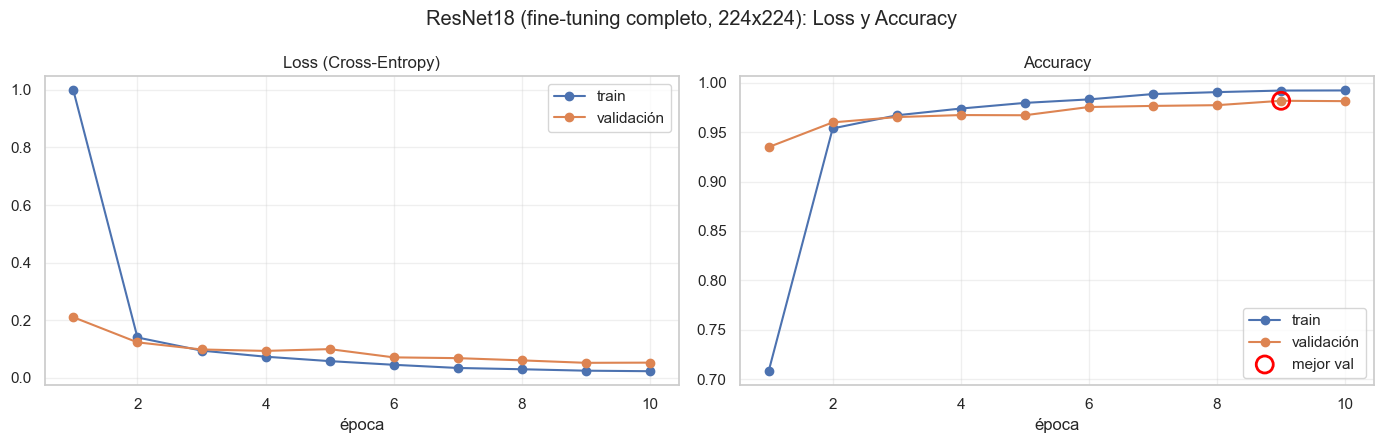

In [26]:
resnet_hr, hist_hr, _ = train_resnet("all", "ResNet18 fine-tuning 224px", loaders=hires_loaders)
fig = plot_history(hist_hr, "ResNet18 (fine-tuning completo, 224x224): Loss y Accuracy")
savefig(fig, "curvas_resnet_finetuning_224"); plt.show()

### 8.4 Evaluación en test de los modelos de transfer learning

In [27]:
tl_models = {
    "ResNet18 layer4+fc": (resnet_l4, tl_loaders),
    "ResNet18 fine-tuning": (resnet_ft, tl_loaders),
    "ResNet18 fine-tuning 224px": (resnet_hr, hires_loaders),
}
results_tl = {}
for name, (model, lds) in tl_models.items():
    _, yp_plain, _ = predict(model, lds["test"], DEVICE)
    yt, yp, pr = predict(model, lds["test"], DEVICE, tta=True)
    plain = metrics_summary(yt, yp_plain)
    results_tl[name] = {"y_true": yt, "y_pred": yp, "probs": pr, **metrics_summary(yt, yp),
                        "accuracy_sin_tta": plain["accuracy"], "f1_macro_sin_tta": plain["f1_macro"]}
    print(f"{name:<28} sin TTA: acc {plain['accuracy']:.4f} F1 {plain['f1_macro']:.4f} | "
          f"con TTA: acc {results_tl[name]['accuracy']:.4f} F1 {results_tl[name]['f1_macro']:.4f}")

best_tl_name = max(results_tl, key=lambda k: results_tl[k]["f1_macro"])
best_tl = results_tl[best_tl_name]
print("\nMejor variante de transfer learning:", best_tl_name)
report_df(best_tl["y_true"], best_tl["y_pred"])

ResNet18 layer4+fc           sin TTA: acc 0.9581 F1 0.9568 | con TTA: acc 0.9752 F1 0.9743
ResNet18 fine-tuning         sin TTA: acc 0.9704 F1 0.9700 | con TTA: acc 0.9774 F1 0.9770
ResNet18 fine-tuning 224px   sin TTA: acc 0.9852 F1 0.9847 | con TTA: acc 0.9859 F1 0.9855

Mejor variante de transfer learning: ResNet18 fine-tuning 224px


,precision,recall,f1-score,support
AnnualCrop,0.9966,0.9700,0.9831,300.0000
Forest,0.9771,0.9967,0.9868,300.0000
HerbaceousVegetation,0.9832,0.9767,0.9799,300.0000
Highway,0.9840,0.9840,0.9840,250.0000
Industrial,0.9960,0.9920,0.9940,250.0000
Pasture,0.9848,0.9750,0.9799,200.0000
PermanentCrop,0.9606,0.9760,0.9683,250.0000
Residential,0.9967,1.0000,0.9983,300.0000
River,0.9763,0.9880,0.9821,250.0000
SeaLake,1.0000,0.9967,0.9983,300.0000


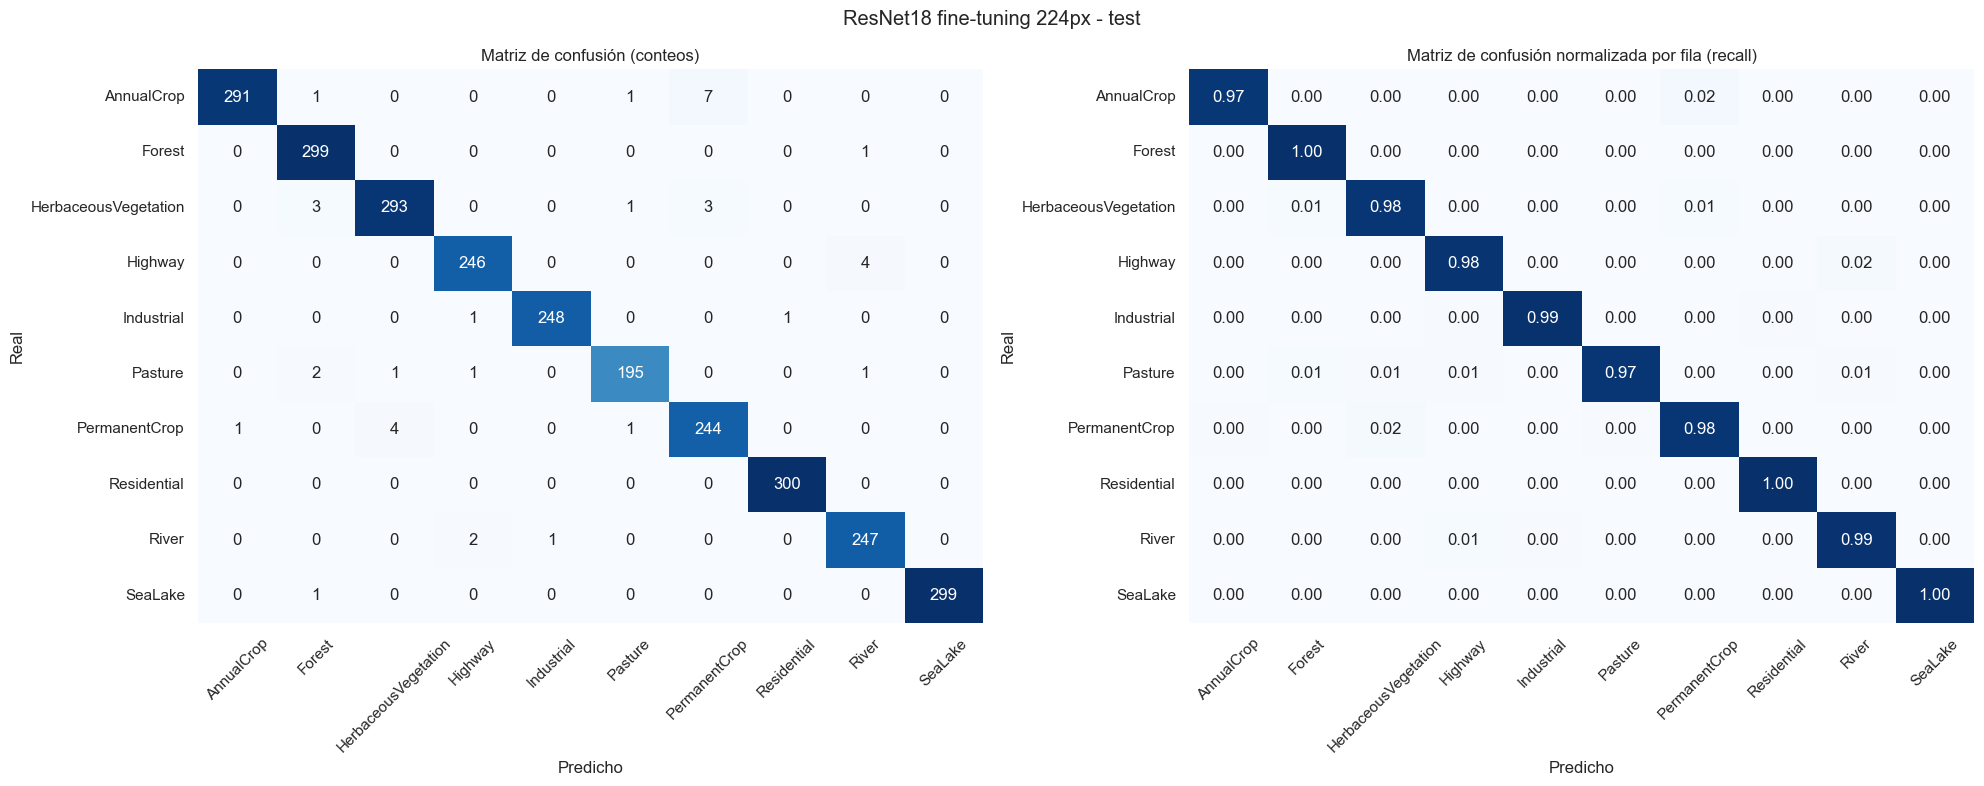

,real,predicho,errores_custom,errores_ResNet18 fine-tuning 224px
0,HerbaceousVegetation,PermanentCrop,12,3.0000
1,AnnualCrop,PermanentCrop,8,7.0000
2,Industrial,Residential,6,1.0000
3,PermanentCrop,HerbaceousVegetation,4,4.0000
4,Pasture,PermanentCrop,3,0.0000
5,Pasture,Forest,3,2.0000
6,River,Highway,2,2.0000
7,HerbaceousVegetation,Forest,2,3.0000
8,Forest,River,1,1.0000
9,HerbaceousVegetation,Pasture,1,1.0000


In [28]:
fig, cm_tl = plot_confusion_matrix(best_tl["y_true"], best_tl["y_pred"], title=f"{best_tl_name} - test")
savefig(fig, "confusion_resnet"); plt.show()

# ¿Qué confusiones se mantienen y cuáles resuelve el transfer learning?
conf_cmp = (
    top_confusions(cm_custom, k=10).rename(columns={"n_errores": "errores_custom"})
    .merge(top_confusions(cm_tl, k=45).rename(columns={"n_errores": f"errores_{best_tl_name}"})
           [["real", "predicho", f"errores_{best_tl_name}"]],
           on=["real", "predicho"], how="left")
    .fillna({f"errores_{best_tl_name}": 0})
    .drop(columns="pct_de_la_clase_real")
)
conf_cmp

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


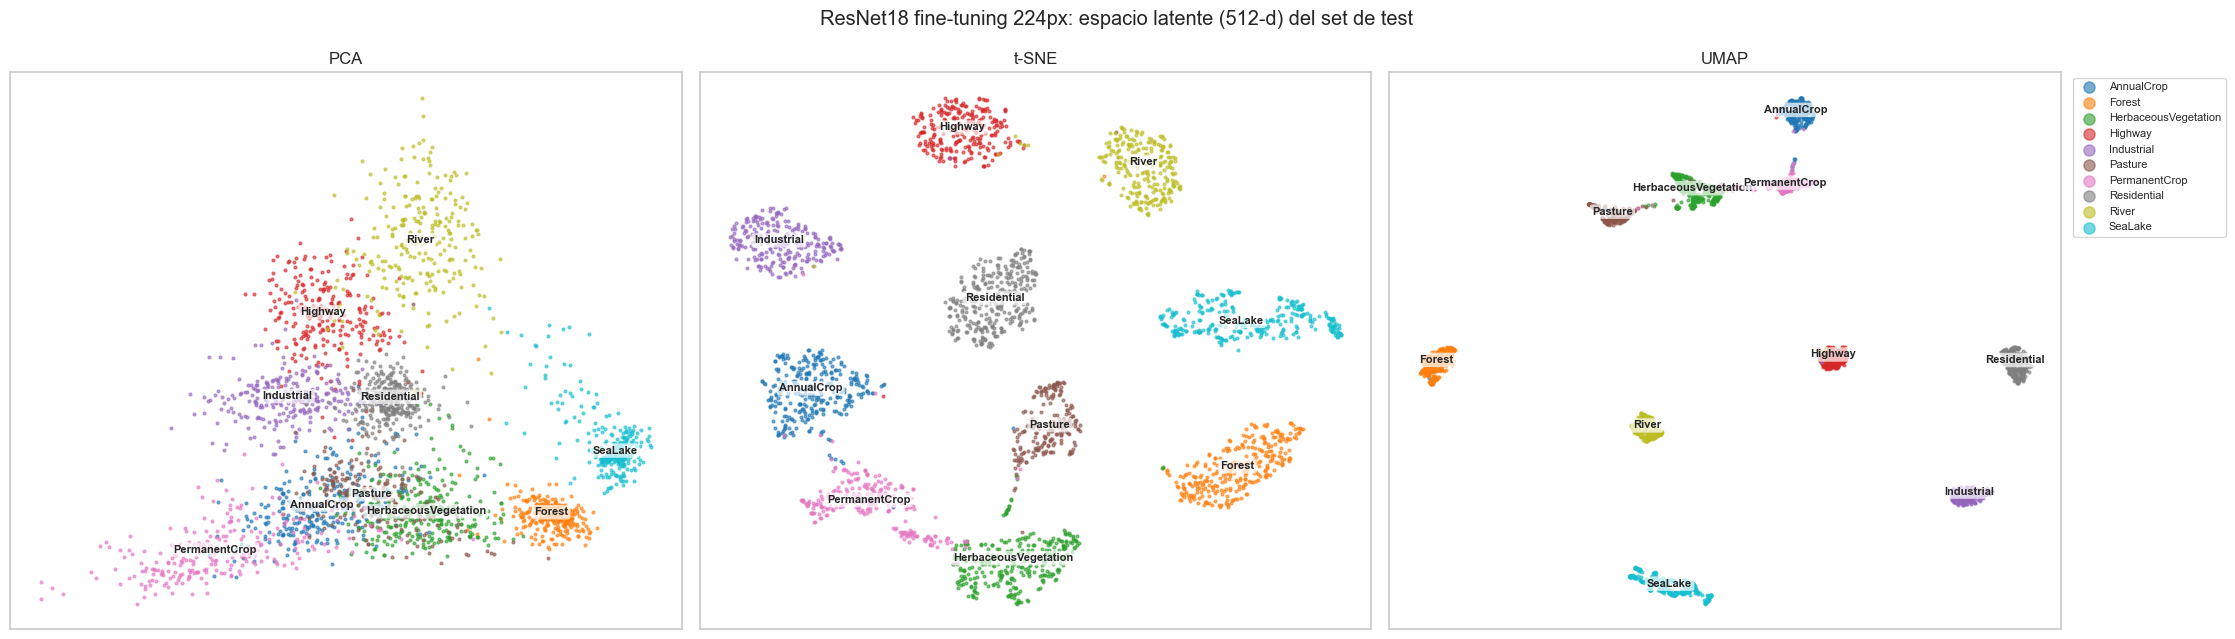

,espacio,silhouette,modelo
0,latente (128-d),0.7150,CNN custom
1,t-SNE 2D,0.6568,CNN custom
2,latente (512-d),0.3929,ResNet18 fine-tuning 224px
3,t-SNE 2D,0.6604,ResNet18 fine-tuning 224px


In [29]:
# Espacio latente de la mejor ResNet (512-d tras el average pooling)
best_tl_model, best_tl_loaders = tl_models[best_tl_name]
feats_tl, labels_tl = extract_features(best_tl_model, best_tl_loaders["test"], DEVICE)
emb_tl = {"PCA": project(feats_tl, "pca"), "t-SNE": project(feats_tl, "tsne"),
          "UMAP": project(feats_tl, "umap")}
fig = plot_embeddings(emb_tl, labels_tl, title=f"{best_tl_name}: espacio latente (512-d) del set de test")
savefig(fig, "latente_resnet"); plt.show()

pd.concat([
    separability_scores(feats_c, labels_c, {"t-SNE 2D": emb_custom["t-SNE"]}).assign(modelo="CNN custom"),
    separability_scores(feats_tl, labels_tl, {"t-SNE 2D": emb_tl["t-SNE"]}).assign(modelo=best_tl_name),
], ignore_index=True)

## 9. Comparación: CNN custom vs Transfer Learning

Comparamos según lo que pide la consigna:

- **Velocidad de convergencia:** épocas (y minutos) necesarios para llegar a
  90% / 95% de accuracy de validación, y forma de las curvas.
- **Rendimiento final:** accuracy y F1-macro en test.
- **Tiempo de cómputo por época:** promedio del tiempo de entrenamiento por
  época (sin la primera, que incluye el *warm-up* de CUDA/cuDNN).

Las métricas de test se reportan sin y con TTA.

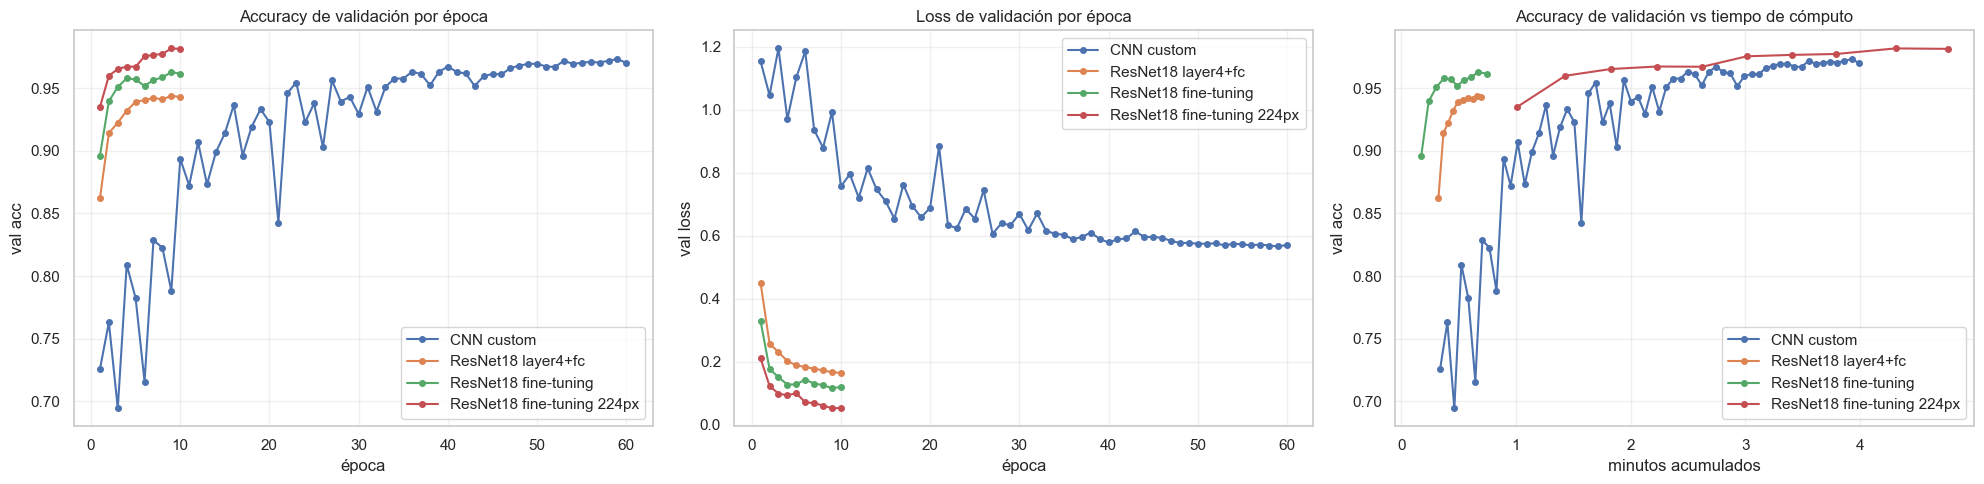

In [30]:
histories = {"CNN custom": hist_custom, "ResNet18 layer4+fc": hist_l4,
             "ResNet18 fine-tuning": hist_ft, "ResNet18 fine-tuning 224px": hist_hr}
fig = plot_comparison(histories)
savefig(fig, "comparacion_curvas"); plt.show()

In [31]:
models_info = {"CNN custom": custom_model, **{k: m for k, (m, _) in tl_models.items()}}
tests = {"CNN custom": {**test_custom, "accuracy_sin_tta": test_custom_plain["accuracy"],
                        "f1_macro_sin_tta": test_custom_plain["f1_macro"]},
         **results_tl}

rows = []
for name, h in histories.items():
    p = count_params(models_info[name])
    t_ep = h["train_time_s"].iloc[1:] if len(h) > 1 else h["train_time_s"]
    rows.append({
        "modelo": name,
        "params_totales": p["total"],
        "params_entrenables": p["trainable"],
        "épocas": len(h),
        "val_acc_época_1": h["val_acc"].iloc[0],
        "épocas_hasta_90%": epochs_to_reach(h, 0.90),
        "épocas_hasta_95%": epochs_to_reach(h, 0.95),
        "mejor_val_acc": h["val_acc"].max(),
        "seg_por_época_train": t_ep.mean(),
        "min_totales": h["elapsed_s"].iloc[-1] / 60,
        "test_acc_sin_tta": tests[name]["accuracy_sin_tta"],
        "test_f1_sin_tta": tests[name]["f1_macro_sin_tta"],
        "test_accuracy": tests[name]["accuracy"],
        "test_f1_macro": tests[name]["f1_macro"],
    })
comparison_df = pd.DataFrame(rows).set_index("modelo")
comparison_df.to_csv(config.OUTPUTS_DIR / "comparacion_modelos.csv")
comparison_df.T

modelo,CNN custom,ResNet18 layer4+fc,ResNet18 fine-tuning,ResNet18 fine-tuning 224px
params_totales,1207402.0000,11181642.0000,11181642.0000,11181642.0000
params_entrenables,1207402.0000,8398858.0000,11181642.0000,11181642.0000
épocas,60.0000,10.0000,10.0000,10.0000
val_acc_época_1,0.7257,0.8620,0.8961,0.9348
épocas_hasta_90%,12.0000,2.0000,2.0000,1.0000
épocas_hasta_95%,23.0000,NaN,3.0000,2.0000
mejor_val_acc,0.9731,0.9439,0.9628,0.9817
seg_por_época_train,3.4404,2.2128,3.5151,22.5936
min_totales,3.9925,0.6984,0.7453,4.7672
test_acc_sin_tta,0.9785,0.9581,0.9704,0.9852


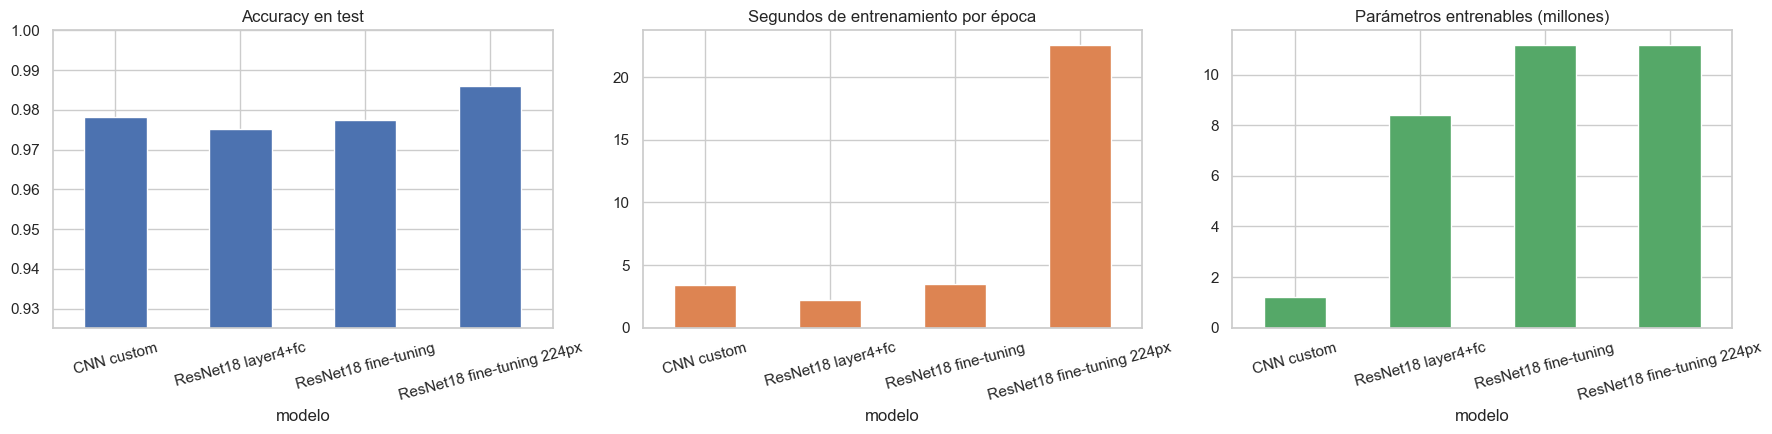

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
comparison_df["test_accuracy"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_ylim(max(0, comparison_df["test_accuracy"].min() - 0.05), 1)
axes[0].set_title("Accuracy en test")
comparison_df["seg_por_época_train"].plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Segundos de entrenamiento por época")
(comparison_df["params_entrenables"] / 1e6).plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title("Parámetros entrenables (millones)")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); savefig(fig, "comparacion_barras"); plt.show()

**Discusión de la comparación:**

- **Velocidad de convergencia:** es la ventaja más clara del transfer
  learning. ResNet18 con fine-tuning arranca en 89,6% (64 px) y **93,5%
  (224 px)** después de **una sola época**, y pasa el 95% en la época 3 y 2
  respectivamente. La CNN custom necesita 12 épocas para el 90% y 23 para
  el 95%. Partir de filtros ya entrenados (bordes, colores, texturas) evita
  aprenderlos desde cero, y las curvas de ResNet son además mucho más
  estables.
- **Rendimiento final:**
  - El mejor modelo es **ResNet18 con fine-tuning a 224 px: 98,59% en test
    con TTA** (98,52% sin TTA; F1-macro 0,986), con solo 38 errores. Reduce
    sobre todo `HerbaceousVegetation` → `PermanentCrop` (12 → 3) e
    `Industrial` → `Residential` (6 → 1) respecto de la CNN custom, y
    también ayuda mucho a `PermanentCrop` (F1 0,968).
  - Subir la resolución importa: a 64 px, `layer4` termina con un mapa de
    2×2; a 224 px, de 7×7, y los filtros ven los objetos a la escala para la
    que se preentrenaron.
  - A 64 px, el fine-tuning (97,7% con TTA) y la **CNN custom (97,8%)**
    empatan: la diferencia es de 1-2 imágenes. Una red 9 veces más chica,
    entrenada desde cero, iguala a ResNet18 a la misma resolución.
- **Congelar el backbone (`layer4`+`fc`) es la peor opción sin TTA**
  (95,8%): se estanca en ~94% de validación porque las capas congeladas
  extraen features de ImageNet (fotos de objetos de costado, a 224 px) no
  adaptados a texturas cenitales de 64 px (*domain shift*).
- **El TTA ayuda más cuanto menos adaptado está el modelo:**
  - ResNet con backbone congelado: +1,7 puntos (95,8% → 97,5%).
  - Fine-tuning a 64 px: +0,7.
  - Fine-tuning a 224 px: +0,07.
  - CNN custom: 0.

  Promediar las 8 orientaciones corrige errores que dependen de la
  orientación. Los modelos que se adaptaron completamente al dominio ya son
  invariantes y no tienen esos errores.
- **Tiempo de cómputo por época** (con el pipeline en GPU, la comparación
  ahora refleja el costo real de cada modelo):
  - **ResNet18 a 64 px (3,5 s) cuesta lo mismo que la CNN custom (3,4 s)**,
    aunque tiene 9 veces más parámetros. ResNet reduce la imagen 4 veces en
    sus dos primeras capas (convolución con stride 2 + max pooling), así que
    a 64 px procesa mapas chicos. La CNN custom, en cambio, aplica sus
    convoluciones sobre la imagen completa de 64×64 en el primer bloque. El
    número de parámetros no determina el costo: lo determinan las
    operaciones por píxel y la resolución a la que se hacen.
  - **Congelar el backbone abarata la época un 37%** (2,2 s vs 3,5 s): no se
    calculan los gradientes de las capas congeladas.
  - **A 224 px la época cuesta 6,4 veces más** (22,6 s): hay 12 veces más
    píxeles.
- **Tiempo total y trade-off:** la variante de 224 px tarda 4,8 minutos,
  casi lo mismo que la CNN custom (4,0 min), y da 0,8 puntos más. El
  fine-tuning a 64 px logra el mismo nivel que la CNN custom en **menos de
  1 minuto**. Como se ve en el gráfico de accuracy vs minutos, el
  transfer learning domina en tiempo para cualquier nivel de accuracy.
  La CNN custom solo tiene sentido si se necesita un modelo liviano para
  inferencia (1,2 M parámetros vs 11,2 M).
- **Variación entre corridas:** ResNet18 a 64 px dio 97,33% en la primera
  corrida y 97,04% en esta, con la misma configuración salvo el pipeline.
  Diferencias de ese tamaño (≤ 0,3-0,5 puntos, unas 10 imágenes) son ruido
  y no deben interpretarse como mejoras.

## 10. Conclusiones finales

- **Datos y augmentation:** las imágenes cenitales no tienen orientación
  canónica, así que las augmentations geométricas (rotaciones de 90° +
  flips, que cubren las 8 orientaciones sin bordes vacíos) son las
  adecuadas. Con dropout, weight decay y *label smoothing* el entrenamiento
  terminó sin overfitting.
- **CNN custom:** con 1,2 M de parámetros alcanza **97,85% de accuracy y F1
  macro 0,978 en test**. El flujo de gradientes es sano en todas las capas
  (cociente máximo/mínimo de 6), en contraste con una red con sigmoide y
  sin BatchNorm, donde el gradiente de la primera capa es 2·10⁸ veces menor
  que el de la última. BatchNorm, ReLU y la inicialización de He son las
  responsables.
- **Errores:** se concentran en el grupo de cultivos y vegetación, con
  `PermanentCrop` como "clase sumidero", y en `Industrial` → `Residential`.
  Son errores entre clases semánticamente vecinas, de color casi idéntico y
  con diferencias en parte temporales.
- **Espacio latente:** antes de la capa final las clases forman clusters
  claros (silhouette 0,72; 0,78 en UMAP), frente a −0,11 en los píxeles
  crudos. Los solapamientos coinciden con las confusiones, y el *label
  smoothing* compactó notablemente los clusters respecto de la primera
  versión (0,51 → 0,72).
- **Transfer learning:** ResNet18 con fine-tuning completo a 224 px es el
  mejor modelo (**98,59%**, F1 0,986) y converge en 1-2 épocas. A 64 px
  empata con la CNN custom pero en menos de un minuto de entrenamiento.
  Congelar el backbone rinde peor por el *domain shift*.
- **Optimización:** llevar los datos y la augmentation a la GPU bajó la
  lectura de una época de train de ~11-24 s a 0,74 s, e hizo el
  entrenamiento ~3 veces más rápido por época. Eso permitió duplicar las
  épocas de la CNN custom y sumar la variante a 224 px sin aumentar el
  tiempo total.
- **Recomendación:** fine-tuning completo de ResNet18 a 224 px si el
  objetivo es la máxima accuracy, y la CNN custom si se necesita un modelo
  liviano. Para seguir mejorando en el grupo vegetal, el paso natural es
  usar las 13 bandas multiespectrales de Sentinel-2 (el infrarrojo cercano
  es muy sensible al tipo y estado de la vegetación) o series temporales de
  imágenes.